# Wall shear: Re = 10, Ca = 0.01, θ = 45°, t = 1800

Uses the current `ClosureData` format and the snapshot-slicing approach in `CorrectionTerms_Across_Sims_NewData.ipynb` and `verify_thinfilm_equation.ipynb`.

The stored `dudy_wall` is the nondimensional wall shear $\tau_w=(\partial u/\partial z)_{z=0}$ used in these notebooks. Its contribution to the momentum equation is $-\tau_w/Re$. This plot shows $\tau_w$, over the selected spatial range and no additional smoothing.

The HDF5 key `dudy_wall` retains its original name; the wall-normal coordinate is denoted by $z$ throughout the analysis. $h_N$ denotes the reference Nusselt film thickness (stored as `Parameters/h0` in the raw file).

In [1]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

RE = 10
CA = 0.01
THETA = 45
TIME_TARGET = 1800.0
X_LIMITS = (450, 600)

DATA_DIR = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/"
    "thinfilm-closure-ml/datasets/BasC/param_space/ClosureData"
)
ca_tag = f"{CA:.3f}".replace(".", "_")
theta_tag = f"{THETA:g}".replace(".", "_")
filepath = DATA_DIR / f"thinfilm_closure_data_Re{RE:03d}_Ca{ca_tag}_theta{theta_tag}.h5"


In [2]:
with h5py.File(filepath, "r") as f:
    x = np.asarray(f["x"][:], dtype=float).reshape(-1)
    t = np.asarray(f["t"][:], dtype=float).reshape(-1)
    matches = np.flatnonzero(np.isclose(t, TIME_TARGET, rtol=0, atol=1e-8))
    if matches.size != 1:
        raise ValueError(f"Expected one snapshot at t={TIME_TARGET:g}; found {matches.size}.")
    it = int(matches[0])
    selected_time = float(t[it])
    def read_profile(name):
        dataset = f[name]
        # Read only the requested time slice.
        if dataset.shape == (x.size, t.size):
            return np.asarray(dataset[:, it], dtype=float)
        if dataset.shape == (t.size, x.size):
            return np.asarray(dataset[it, :], dtype=float)
        raise ValueError(f"Unexpected {name} shape: {dataset.shape}")

    height = read_profile("h")
    tau_wall = read_profile("dudy_wall")
    parameters = {name: float(f["parameters"][name][()])
                  for name in ("Re", "Ca", "angle")}

np.testing.assert_allclose(
    [parameters["Re"], parameters["Ca"], np.rad2deg(parameters["angle"])],
    [RE, CA, THETA], rtol=1e-8, atol=1e-10,
)
if not np.all(np.isfinite(x)) or np.any(np.diff(x) <= 0):
    raise ValueError("Spatial coordinates must be finite and strictly increasing.")
if not np.all(np.isfinite(height)) or np.any(height <= 0):
    raise ValueError("Film height must be finite and positive.")
if not np.all(np.isfinite(tau_wall)):
    raise ValueError("Wall shear contains NaN or Inf.")

print(f"Loaded: {filepath.name}")
print(f"Selected time: {selected_time:g} (exact requested snapshot)")
print(f"Spatial points: {x.size:,}; x range: [{x.min():g}, {x.max():g}]")
print(f"Wall shear range: [{tau_wall.min():.6g}, {tau_wall.max():.6g}]")


Loaded: thinfilm_closure_data_Re010_Ca0_010_theta45.h5
Selected time: 1800 (exact requested snapshot)
Spatial points: 16,384; x range: [0.0244141, 799.976]
Wall shear range: [-2.19702, 5.33795]


In [3]:
from scipy.signal import find_peaks

# Detect local minima using the complete curve, then restrict to the view.
trough_indices, _ = find_peaks(-tau_wall)
trough_indices = trough_indices[
    (x[trough_indices] >= X_LIMITS[0])
    & (x[trough_indices] <= X_LIMITS[1])
]
negative_trough_indices = trough_indices[tau_wall[trough_indices] < 0]
if negative_trough_indices.size == 0:
    raise ValueError("No negative wall shear troughs in the selected range.")
selected_index = int(negative_trough_indices[np.argmin(tau_wall[negative_trough_indices])])
selected_x = float(x[selected_index])

print("Local wall shear troughs in the selected range:")
print(f"{'x/h_N':>14} {'tau_wall':>14}")
for index in trough_indices:
    marker = "  <-- selected (deepest negative trough)" if index == selected_index else ""
    print(f"{x[index]:14.6f} {tau_wall[index]:14.6f}{marker}")


Local wall shear troughs in the selected range:
         x/h_N       tau_wall
    457.543945       3.812269
    467.309570      -0.002201
    475.756836      -1.699099  <-- selected (deepest negative trough)
    480.932617       1.459836
    486.499023       1.143233
    491.918945       2.312538
    497.192383       2.343097
    521.166992       3.401894
    530.297852      -1.094225
    538.208008       2.063226
    553.833008       3.249724
    563.745117      -0.714434
    571.606445       1.457080
    579.418945       2.054966


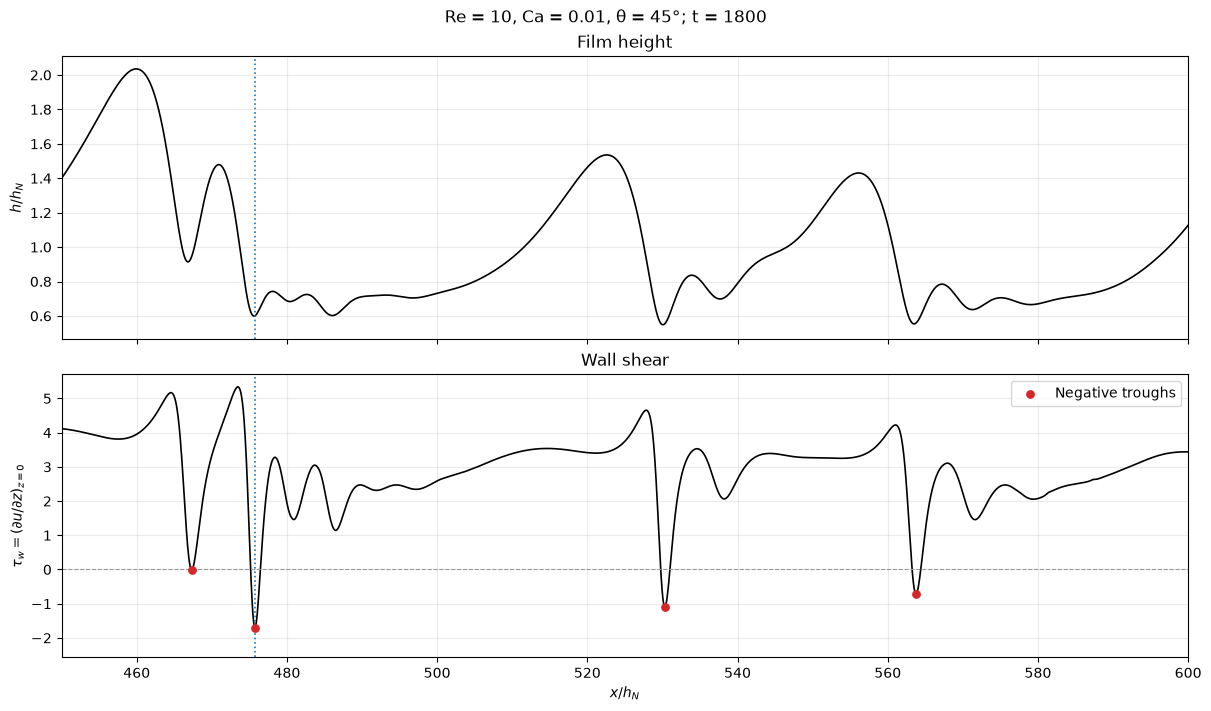

In [4]:
fig, axes = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, constrained_layout=True
)
axes[0].plot(x, height, color="black", linewidth=1.2)
axes[0].set_ylabel(r"$h/h_N$")
axes[0].set_title("Film height")

axes[1].plot(x, tau_wall, color="black", linewidth=1.2)
axes[1].axhline(0, color="0.6", linewidth=0.8, linestyle="--")
axes[1].set_xlabel(r"$x/h_N$")
axes[1].set_ylabel(r"$\tau_w = (\partial u/\partial z)_{z=0}$")
axes[1].set_title("Wall shear")

axes[1].scatter(x[negative_trough_indices], tau_wall[negative_trough_indices],
                color="tab:red", s=28, zorder=3, label="Negative troughs")
for ax in axes:
    ax.axvline(selected_x, color="tab:blue", linestyle=":", linewidth=1.2)
axes[1].legend()

fig.suptitle(
    f"Re = {RE}, Ca = {CA:g}, θ = {THETA}°; t = {selected_time:g}"
)
for ax in axes:
    ax.grid(alpha=0.25)
    if X_LIMITS is not None:
        ax.set_xlim(*X_LIMITS)
plt.show()


## Liquid velocity profile at the deepest negative wall-shear trough

Load the raw flow snapshot at the same time, reconstruct cell centers from mesh vertices, and select the nearest streamwise column. The second mesh coordinate is called $z$. Use only fully liquid cells ($f \geq 1-10^{-6}$), excluding mixed interface and gas cells. Add the no-slip wall value $u(0)=0$. The profile stops at the last fully liquid cell; no interface velocity is extrapolated.

In [5]:
case_dir = DATA_DIR.parent / f"Re{RE:03d}_Ca{ca_tag}_theta{theta_tag}"
snapshot_path = case_dir / "output" / f"snapshot_{selected_time:06.0f}.h5"
LIQUID_THRESHOLD = 1.0 - 1e-6

with h5py.File(snapshot_path, "r") as raw:
    raw_time = float(raw["Parameters/time"][()])
    np.testing.assert_allclose(raw_time, selected_time, rtol=0, atol=1e-8)
    np.testing.assert_allclose(
        [float(raw["Parameters/Re"][()]), float(raw["Parameters/Ca"][()]),
         np.rad2deg(float(raw["Parameters/angle"][()]))],
        [RE, CA, THETA], rtol=1e-8, atol=1e-10,
    )
    # Same vertex-averaging reconstruction used in LavalleOrigins.ipynb.
    points = raw["Geometry/Points"][:]
    topology = raw["Topology"][:]
    centers = np.zeros((topology.shape[0], 2), dtype=float)
    for corner in range(topology.shape[1]):
        centers += points[topology[:, corner], :2] / topology.shape[1]
    del points, topology
    raw_x = np.unique(np.round(centers[:, 0], 12))
    profile_x = float(raw_x[np.argmin(np.abs(raw_x - selected_x))])
    column_indices = np.flatnonzero(np.isclose(centers[:, 0], profile_x, rtol=0, atol=1e-10))
    column_indices.sort()  # h5py fancy indexing requires increasing indices.
    z_column = centers[column_indices, 1]
    u_column = np.asarray(raw["Cells/u.x"][column_indices, 0])
    liquid_fraction = np.asarray(raw["Cells/f"][column_indices]).reshape(-1)
    del centers

order = np.argsort(z_column)
z_column, u_column, liquid_fraction = (
    values[order] for values in (z_column, u_column, liquid_fraction)
)
if not all(np.all(np.isfinite(values)) for values in (z_column, u_column, liquid_fraction)):
    raise ValueError("Non-finite raw profile values.")
liquid = liquid_fraction >= LIQUID_THRESHOLD
if np.count_nonzero(liquid) < 2:
    raise ValueError("Insufficient fully liquid cells in the selected column.")
z_liquid = np.r_[0.0, z_column[liquid]]
u_liquid = np.r_[0.0, u_column[liquid]]
# Compare the raw wall stencil with the stored gradient at this location.
dz = z_column[1] - z_column[0]
np.testing.assert_allclose(np.diff(z_column), dz, rtol=1e-8, atol=1e-10)
np.testing.assert_allclose(z_column[0], 0.5 * dz, rtol=1e-8, atol=1e-10)
raw_wall_gradient = np.dot([3675., -1225., 441., -75.], u_column[:4]) / (840. * dz)
print(f"Loaded: {snapshot_path}")
print(f"Raw time: {raw_time:g}; selected x/h_N: {selected_x:.9f}; raw column: {profile_x:.9f}")
print(f"Closure tau_wall: {tau_wall[selected_index]:.6g}; raw wall gradient: {raw_wall_gradient:.6g}")
print(f"Fully liquid cells: {np.count_nonzero(liquid)}; minimum liquid u: {u_column[liquid].min():.6g}")


Loaded: /blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/datasets/BasC/param_space/Re010_Ca0_010_theta45/output/snapshot_001800.h5
Raw time: 1800; selected x/h_N: 475.756835938; raw column: 475.756835938
Closure tau_wall: -1.6991; raw wall gradient: -1.6991
Fully liquid cells: 12; minimum liquid u: -0.0866031


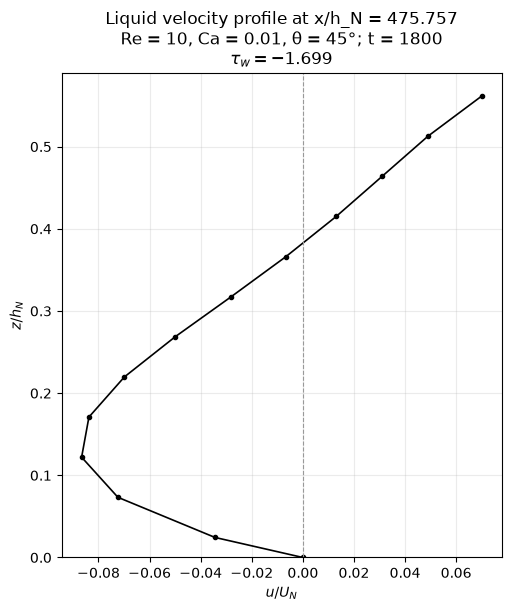

In [6]:
fig, ax = plt.subplots(figsize=(5, 6), constrained_layout=True)
ax.plot(u_liquid, z_liquid, "o-", markersize=3, linewidth=1.2, color="black")
ax.axvline(0, color="0.6", linestyle="--", linewidth=0.8)
ax.set_xlabel(r"$u/U_N$")
ax.set_ylabel(r"$z/h_N$")
ax.set_ylim(bottom=0)
ax.set_title(
    f"Liquid velocity profile at x/h_N = {profile_x:.3f}\n"
    f"Re = {RE}, Ca = {CA:g}, θ = {THETA}°; t = {raw_time:g}\n"
    + rf"$\tau_w = {tau_wall[selected_index]:.3f}$"
)
ax.grid(alpha=0.25)
plt.show()


Saved: /blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/techreport_figures/section1_backflow.pdf


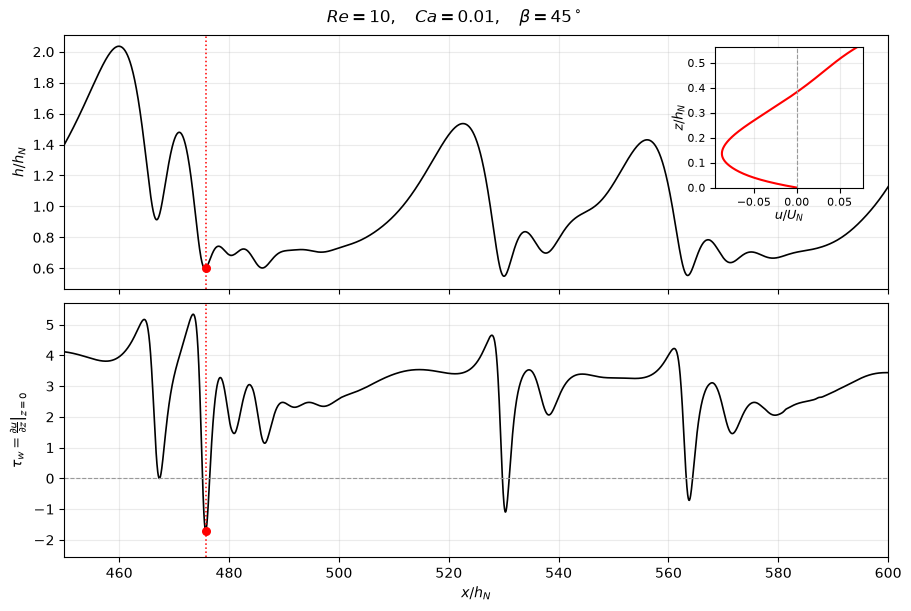

In [7]:
from scipy.interpolate import make_interp_spline

# A cubic interpolating spline provides a smooth profile through the liquid data.
z_smooth = np.linspace(z_liquid[0], z_liquid[-1], 500)
u_smooth = make_interp_spline(z_liquid, u_liquid, k=3)(z_smooth)

# 9 x 6 inches at 100 dpi gives a 900 x 600 pixel canvas.
fig, (ax_height, ax_shear) = plt.subplots(
    2, 1, figsize=(9, 6), dpi=100, sharex=True, constrained_layout=True
)
# Place the velocity profile inside the upper-right of the height panel.
ax_velocity = ax_height.inset_axes([0.79, 0.40, 0.18, 0.55])
ax_velocity.set_facecolor("white")
ax_velocity.tick_params(labelsize=8)

ax_height.plot(x, height, color="black", linewidth=1.2)
ax_height.set_ylabel(r"$h/h_N$")
ax_height.tick_params(axis="x", labelbottom=False)

ax_shear.plot(x, tau_wall, color="black", linewidth=1.2)
ax_shear.axhline(0, color="0.6", linewidth=0.8, linestyle="--")
ax_shear.set_xlabel(r"$x/h_N$")
ax_shear.set_ylabel(r"$\tau_w = \left.\frac{\partial u}{\partial z}\right|_{z=0}$")

for ax, value in ((ax_height, height[selected_index]),
                  (ax_shear, tau_wall[selected_index])):
    ax.axvline(selected_x, color="red", linestyle=":", linewidth=1.1)
    ax.scatter([selected_x], [value], color="red", s=30, zorder=4)
    ax.set_xlim(*X_LIMITS)
    ax.grid(alpha=0.25)

ax_velocity.plot(u_smooth, z_smooth, color="red", linewidth=1.5)
ax_velocity.axvline(0, color="0.6", linewidth=0.8, linestyle="--")
ax_velocity.set_xlabel(r"$u/U_N$", fontsize=9, labelpad=1)
ax_velocity.set_ylabel(r"$z/h_N$", fontsize=9, labelpad=1)
ax_velocity.set_ylim(z_smooth[0], z_smooth[-1])
ax_velocity.grid(alpha=0.25)

fig.suptitle(rf"$Re = {RE},\quad Ca = {CA:g},\quad \beta = {THETA}^\circ$")
output_dir = Path("techreport_figures")
output_dir.mkdir(parents=True, exist_ok=True)
pdf_path = output_dir / "section1_backflow.pdf"
fig.savefig(pdf_path, format="pdf")
print(f"Saved: {pdf_path.resolve()}")
plt.show()


## Simulated parameter space

Markers show simulations with at least 100 HDF5 files in `simulation_file_counts.csv`. Inclination angles are distinguished by red crosses (6.4°), blue circles (45°), and black squares (90°). Open circles and squares preserve visibility where simulations share the same Re and Ca. The figure is exported as `techreport_figures/simulation_availability.pdf`.

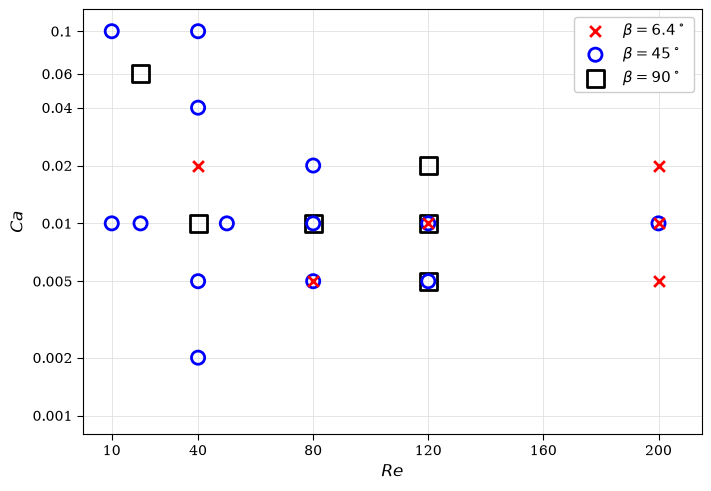

In [8]:
import csv
import re

MIN_H5_FILES = 100
counts_path = DATA_DIR.parent / "simulation_file_counts.csv"
case_counts = {}
pattern = re.compile(r"Re(?P<Re>\d+)_Ca(?P<Ca>\d+_\d+)_theta(?P<beta>\d+(?:_\d+)?)")
with counts_path.open(newline="") as stream:
    for row in csv.DictReader(stream):
        match = pattern.fullmatch(row["simulation_directory"])
        if match is None:
            raise ValueError(f"Unrecognized simulation name: {row['simulation_directory']}")
        case_re = int(match["Re"])
        case_ca = float(match["Ca"].replace("_", "."))
        case_beta = float(match["beta"].replace("_", "."))
        key = (case_re, case_ca, case_beta)
        if key in case_counts:
            raise ValueError(f"Duplicate simulation: {key}")
        case_counts[key] = int(row["num_h5_files"])

re_values = sorted({key[0] for key in case_counts})
ca_values = sorted({key[1] for key in case_counts})
beta_values = sorted({key[2] for key in case_counts})
assert len(beta_values) == 3, "Expected three inclination angles."

# Plot only simulations meeting the availability criterion above.
with plt.rc_context({
    "font.family": "serif", "font.size": 11,
    "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.linewidth": 0.8, "pdf.fonttype": 42,
}):
    fig_available, ax = plt.subplots(figsize=(7, 4.8), constrained_layout=True)
    marker_styles = [("x", "red"), ("o", "blue"), ("s", "black")]
    # Draw larger open squares first so coincident parameter sets remain visible.
    for index in (2, 1, 0):
        case_beta = beta_values[index]
        marker, color = marker_styles[index]
        performed = [(case_re, case_ca)
                     for (case_re, case_ca, angle), count in case_counts.items()
                     if angle == case_beta and count >= MIN_H5_FILES]
        re_plot, ca_plot = np.asarray(performed, dtype=float).T
        style = dict(marker=marker, label=rf"$\beta = {case_beta:g}^\circ$", zorder=3)
        if marker == "x":
            ax.scatter(re_plot, ca_plot, s=60, color=color, linewidths=2.0, **style)
        else:
            ax.scatter(re_plot, ca_plot, s=90 if marker == "o" else 150,
                       facecolors="none", edgecolors=color, linewidths=2.0, **style)
    ax.set_yscale("log")
    ax.set_xlim(0, 215)
    ax.set_ylim(0.0008, 0.13)
    ax.set_xticks([10, 40, 80, 120, 160, 200])
    ax.set_yticks(ca_values, labels=[f"{value:g}" for value in ca_values])
    ax.minorticks_off()
    ax.grid(color="0.88", linewidth=0.6, zorder=0)
    ax.tick_params(direction="out", length=4, width=0.8)
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.set_xlabel(r"$Re$")
    ax.set_ylabel(r"$Ca$")
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="upper right", frameon=True,
              facecolor="white", framealpha=1, edgecolor="0.8")
    output_dir = Path("techreport_figures")
    output_dir.mkdir(parents=True, exist_ok=True)
    availability_pdf = output_dir / "simulation_availability.pdf"
    fig_available.savefig(availability_pdf, format="pdf")
    plt.show()


## Grid refinement: film height from output snapshots at t = 500

Compare `L800` (level 14) and `L800_Level15` (level 15) at Re = 120, Ca = 0.01, β = 45°. Film height is computed directly from the output liquid volume fraction as $h(x)=\sum_j f_j\,\Delta z_j$. Cell centers and cell heights are reconstructed from mesh vertices. No interface files or additional smoothing are used.

L800: t=500; 16,384 columns; Δ/h_N=0.048828125


L800_Level15: t=500; 32,768 columns; Δ/h_N=0.024414062


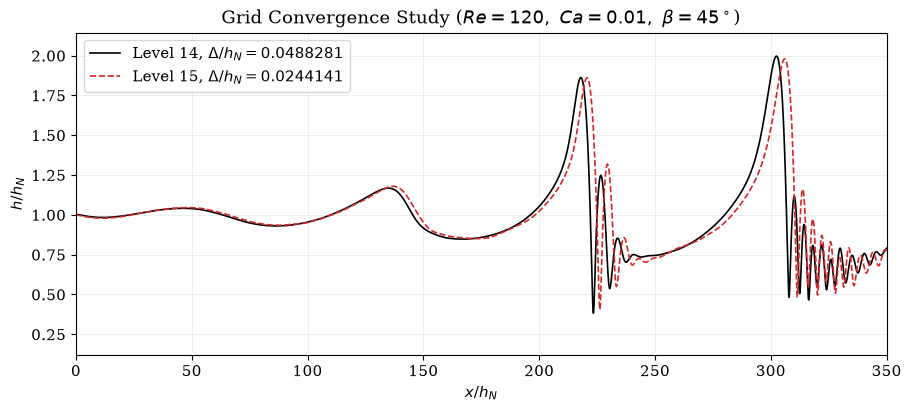

In [9]:
GRID_ROOT = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/basilisk/physics-tests/bc-blowup-fix/length-check"
)
GRID_TIME = 500.0
GRID_X_LIMITS = (0, 350)
grid_cases = [("L800", "black", "-"), ("L800_Level15", "tab:red", "--")]
grid_profiles = []
for case_name, color, linestyle in grid_cases:
    case_path = GRID_ROOT / case_name
    config = {}
    for line in (case_path / "params.in").read_text().splitlines():
        if "=" in line:
            key, value = line.split("=", 1)
            config[key.strip()] = float(value.split("#")[0].strip())
    np.testing.assert_allclose(
        [config["RE"], config["CA"], config["ANGLE_DEG"], config["LX"]],
        [120, 0.01, 45, 800],
    )
    snapshot_path = case_path / "output" / f"snapshot_{GRID_TIME:06.0f}.h5"
    with h5py.File(snapshot_path, "r") as snapshot:
        np.testing.assert_allclose(float(snapshot["Parameters/time"][()]), GRID_TIME)
        np.testing.assert_allclose(
            [float(snapshot["Parameters/Re"][()]), float(snapshot["Parameters/Ca"][()]),
             np.rad2deg(float(snapshot["Parameters/angle"][()]))],
            [120, 0.01, 45],
        )
        points = snapshot["Geometry/Points"][:, :2]
        topology = snapshot["Topology"][:]
        fraction = np.asarray(snapshot["Cells/f"][:], dtype=float).reshape(-1)
    centers_x = np.zeros(topology.shape[0])
    z_lower = np.full(topology.shape[0], np.inf)
    z_upper = np.full(topology.shape[0], -np.inf)
    for corner in range(topology.shape[1]):
        vertices = points[topology[:, corner]]
        centers_x += vertices[:, 0] / topology.shape[1]
        z_lower = np.minimum(z_lower, vertices[:, 1])
        z_upper = np.maximum(z_upper, vertices[:, 1])
    cell_dz = z_upper - z_lower
    if (not np.all(np.isfinite(fraction)) or np.any(fraction < -1e-10)
            or np.any(fraction > 1 + 1e-10) or np.any(cell_dz <= 0)):
        raise ValueError(f"Invalid volume fractions or cell geometry: {case_name}")
    x_grid, columns = np.unique(np.round(centers_x, 12), return_inverse=True)
    # Finite-volume depth integral, including the liquid part of mixed cells.
    h_grid = np.bincount(columns, weights=fraction * cell_dz)
    level = int(config["MAXLEVEL"])
    spacing = config["LX"] / 2**level
    np.testing.assert_allclose(np.diff(x_grid), spacing, rtol=1e-8, atol=1e-10)
    label = rf"Level {level}, $\Delta/h_N = {spacing:.7f}$"
    grid_profiles.append((x_grid, h_grid, color, linestyle, label))
    print(f"{case_name}: t={GRID_TIME:g}; {x_grid.size:,} columns; Δ/h_N={spacing:.8g}")
    del points, topology, fraction, centers_x, z_lower, z_upper, cell_dz, columns, vertices

with plt.rc_context({"font.family": "serif", "font.size": 11, "pdf.fonttype": 42}):
    fig_grid, ax_grid = plt.subplots(figsize=(9, 4), constrained_layout=True)
    for x_grid, h_grid, color, linestyle, label in grid_profiles:
        ax_grid.plot(x_grid, h_grid, color=color, linestyle=linestyle,
                     linewidth=1.2, label=label)
    ax_grid.set_xlim(*GRID_X_LIMITS)
    ax_grid.set_xlabel(r"$x/h_N$")
    ax_grid.set_ylabel(r"$h/h_N$")
    ax_grid.set_title(r"Grid Convergence Study ($Re=120,\ Ca=0.01,\ \beta=45^\circ$)")
    ax_grid.grid(alpha=0.25, linewidth=0.6)
    ax_grid.legend(frameon=True)
    figure_dir = Path("techreport_figures")
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig_grid.savefig(figure_dir / "grid_convergence_t500.pdf", format="pdf")
    plt.show()


## Domain length comparison: L400 and L800

Compare film-height profiles reconstructed from output volume fractions at t = 500, over x/h_N = 0–400. The box marks x/h_N = 380–400, the last 5% of L400, to inspect sensitivity to the shorter domain's outlet condition. Differences in this region alone do not establish their cause; the grid spacings are printed and included in the legend.

L400: t=500; 8,192 columns; Δ/h_N=0.048828125


L800: t=500; 16,384 columns; Δ/h_N=0.048828125


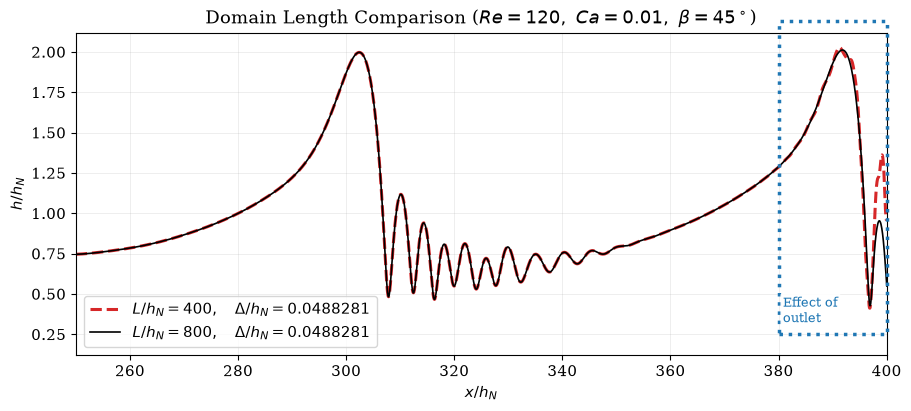

In [10]:
GRID_ROOT = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/basilisk/physics-tests/bc-blowup-fix/length-check"
)
GRID_TIME = 500.0
GRID_X_LIMITS = (250, 400)
grid_cases = [("L400", "tab:red", "--"), ("L800", "black", "-")]
grid_profiles = []
for case_name, color, linestyle in grid_cases:
    case_path = GRID_ROOT / case_name
    config = {}
    for line in (case_path / "params.in").read_text().splitlines():
        if "=" in line:
            key, value = line.split("=", 1)
            config[key.strip()] = float(value.split("#")[0].strip())
    np.testing.assert_allclose(
        [config["RE"], config["CA"], config["ANGLE_DEG"], config["LX"]],
        [120, 0.01, 45, float(case_name[1:])],
    )
    snapshot_path = case_path / "output" / f"snapshot_{GRID_TIME:06.0f}.h5"
    with h5py.File(snapshot_path, "r") as snapshot:
        np.testing.assert_allclose(float(snapshot["Parameters/time"][()]), GRID_TIME)
        np.testing.assert_allclose(
            [float(snapshot["Parameters/Re"][()]), float(snapshot["Parameters/Ca"][()]),
             np.rad2deg(float(snapshot["Parameters/angle"][()]))],
            [120, 0.01, 45],
        )
        points = snapshot["Geometry/Points"][:, :2]
        topology = snapshot["Topology"][:]
        fraction = np.asarray(snapshot["Cells/f"][:], dtype=float).reshape(-1)
    centers_x = np.zeros(topology.shape[0])
    z_lower = np.full(topology.shape[0], np.inf)
    z_upper = np.full(topology.shape[0], -np.inf)
    for corner in range(topology.shape[1]):
        vertices = points[topology[:, corner]]
        centers_x += vertices[:, 0] / topology.shape[1]
        z_lower = np.minimum(z_lower, vertices[:, 1])
        z_upper = np.maximum(z_upper, vertices[:, 1])
    cell_dz = z_upper - z_lower
    if (not np.all(np.isfinite(fraction)) or np.any(fraction < -1e-10)
            or np.any(fraction > 1 + 1e-10) or np.any(cell_dz <= 0)):
        raise ValueError(f"Invalid volume fractions or cell geometry: {case_name}")
    x_grid, columns = np.unique(np.round(centers_x, 12), return_inverse=True)
    # Finite-volume depth integral, including the liquid part of mixed cells.
    h_grid = np.bincount(columns, weights=fraction * cell_dz)
    level = int(config["MAXLEVEL"])
    spacing = config["LX"] / 2**level
    np.testing.assert_allclose(np.diff(x_grid), spacing, rtol=1e-8, atol=1e-10)
    label = rf"$L/h_N = {config['LX']:g},\quad \Delta/h_N = {spacing:.7f}$"
    grid_profiles.append((x_grid, h_grid, color, linestyle, label))
    print(f"{case_name}: t={GRID_TIME:g}; {x_grid.size:,} columns; Δ/h_N={spacing:.8g}")
    del points, topology, fraction, centers_x, z_lower, z_upper, cell_dz, columns, vertices

with plt.rc_context({"font.family": "serif", "font.size": 11, "pdf.fonttype": 42}):
    fig_grid, ax_grid = plt.subplots(figsize=(9, 4), constrained_layout=True)
    for x_grid, h_grid, color, linestyle, label in grid_profiles:
        ax_grid.plot(x_grid, h_grid, color=color, linestyle=linestyle,
                     linewidth=2.2 if color == "tab:red" else 1.2, label=label)
    ax_grid.set_xlim(*GRID_X_LIMITS)
    ax_grid.set_xlabel(r"$x/h_N$")
    ax_grid.set_ylabel(r"$h/h_N$")
    ax_grid.set_title(r"Domain Length Comparison ($Re=120,\ Ca=0.01,\ \beta=45^\circ$)")
    # Last 5% of the shorter domain: x/h_N = 380–400.
    from matplotlib.patches import Rectangle
    outlet_start, outlet_end = 0.95 * 400, 400
    region_values = np.concatenate([
        heights[(coordinates >= outlet_start) & (coordinates <= outlet_end)]
        for coordinates, heights, *_ in grid_profiles
    ])
    lower, upper = region_values.min(), region_values.max()
    padding = max(0.1 * (upper - lower), 0.03)
    ax_grid.add_patch(Rectangle(
        (outlet_start, lower - padding), outlet_end - outlet_start,
        upper - lower + 2 * padding, fill=False, edgecolor="tab:blue",
        linewidth=2.5, linestyle=":", zorder=5, clip_on=False,
    ))
    ax_grid.text(
        outlet_start + 0.04 * (outlet_end - outlet_start), lower - 0.7 * padding,
        "Effect of\noutlet", ha="left", va="bottom", color="tab:blue",
        fontsize=9, zorder=6,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white",
                  edgecolor="none", alpha=0.9),
    )
    ax_grid.grid(alpha=0.25, linewidth=0.6)
    ax_grid.legend(frameon=True)
    figure_dir = Path("techreport_figures")
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig_grid.savefig(figure_dir / "domain_length_comparison_t500.pdf", format="pdf")
    plt.show()


## Combined report figure

Top row: **A** grid convergence, **B** domain-length comparison, **C** parameter space of performed simulations. Bottom row: **D** falling-film schematic with inlet disturbance, **E** backflow with (i) film height, (ii) wall shear, and (iii) liquid velocity profile.

L800: t=500; 16,384 columns; Δ/h_N=0.048828125


L800_Level15: t=500; 32,768 columns; Δ/h_N=0.024414062


L400: t=500; 8,192 columns; Δ/h_N=0.048828125


L800: t=500; 16,384 columns; Δ/h_N=0.048828125
Saved: /blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/codes/data-preprocessing/notebooks/techreport_figures/section1_backflow.pdf


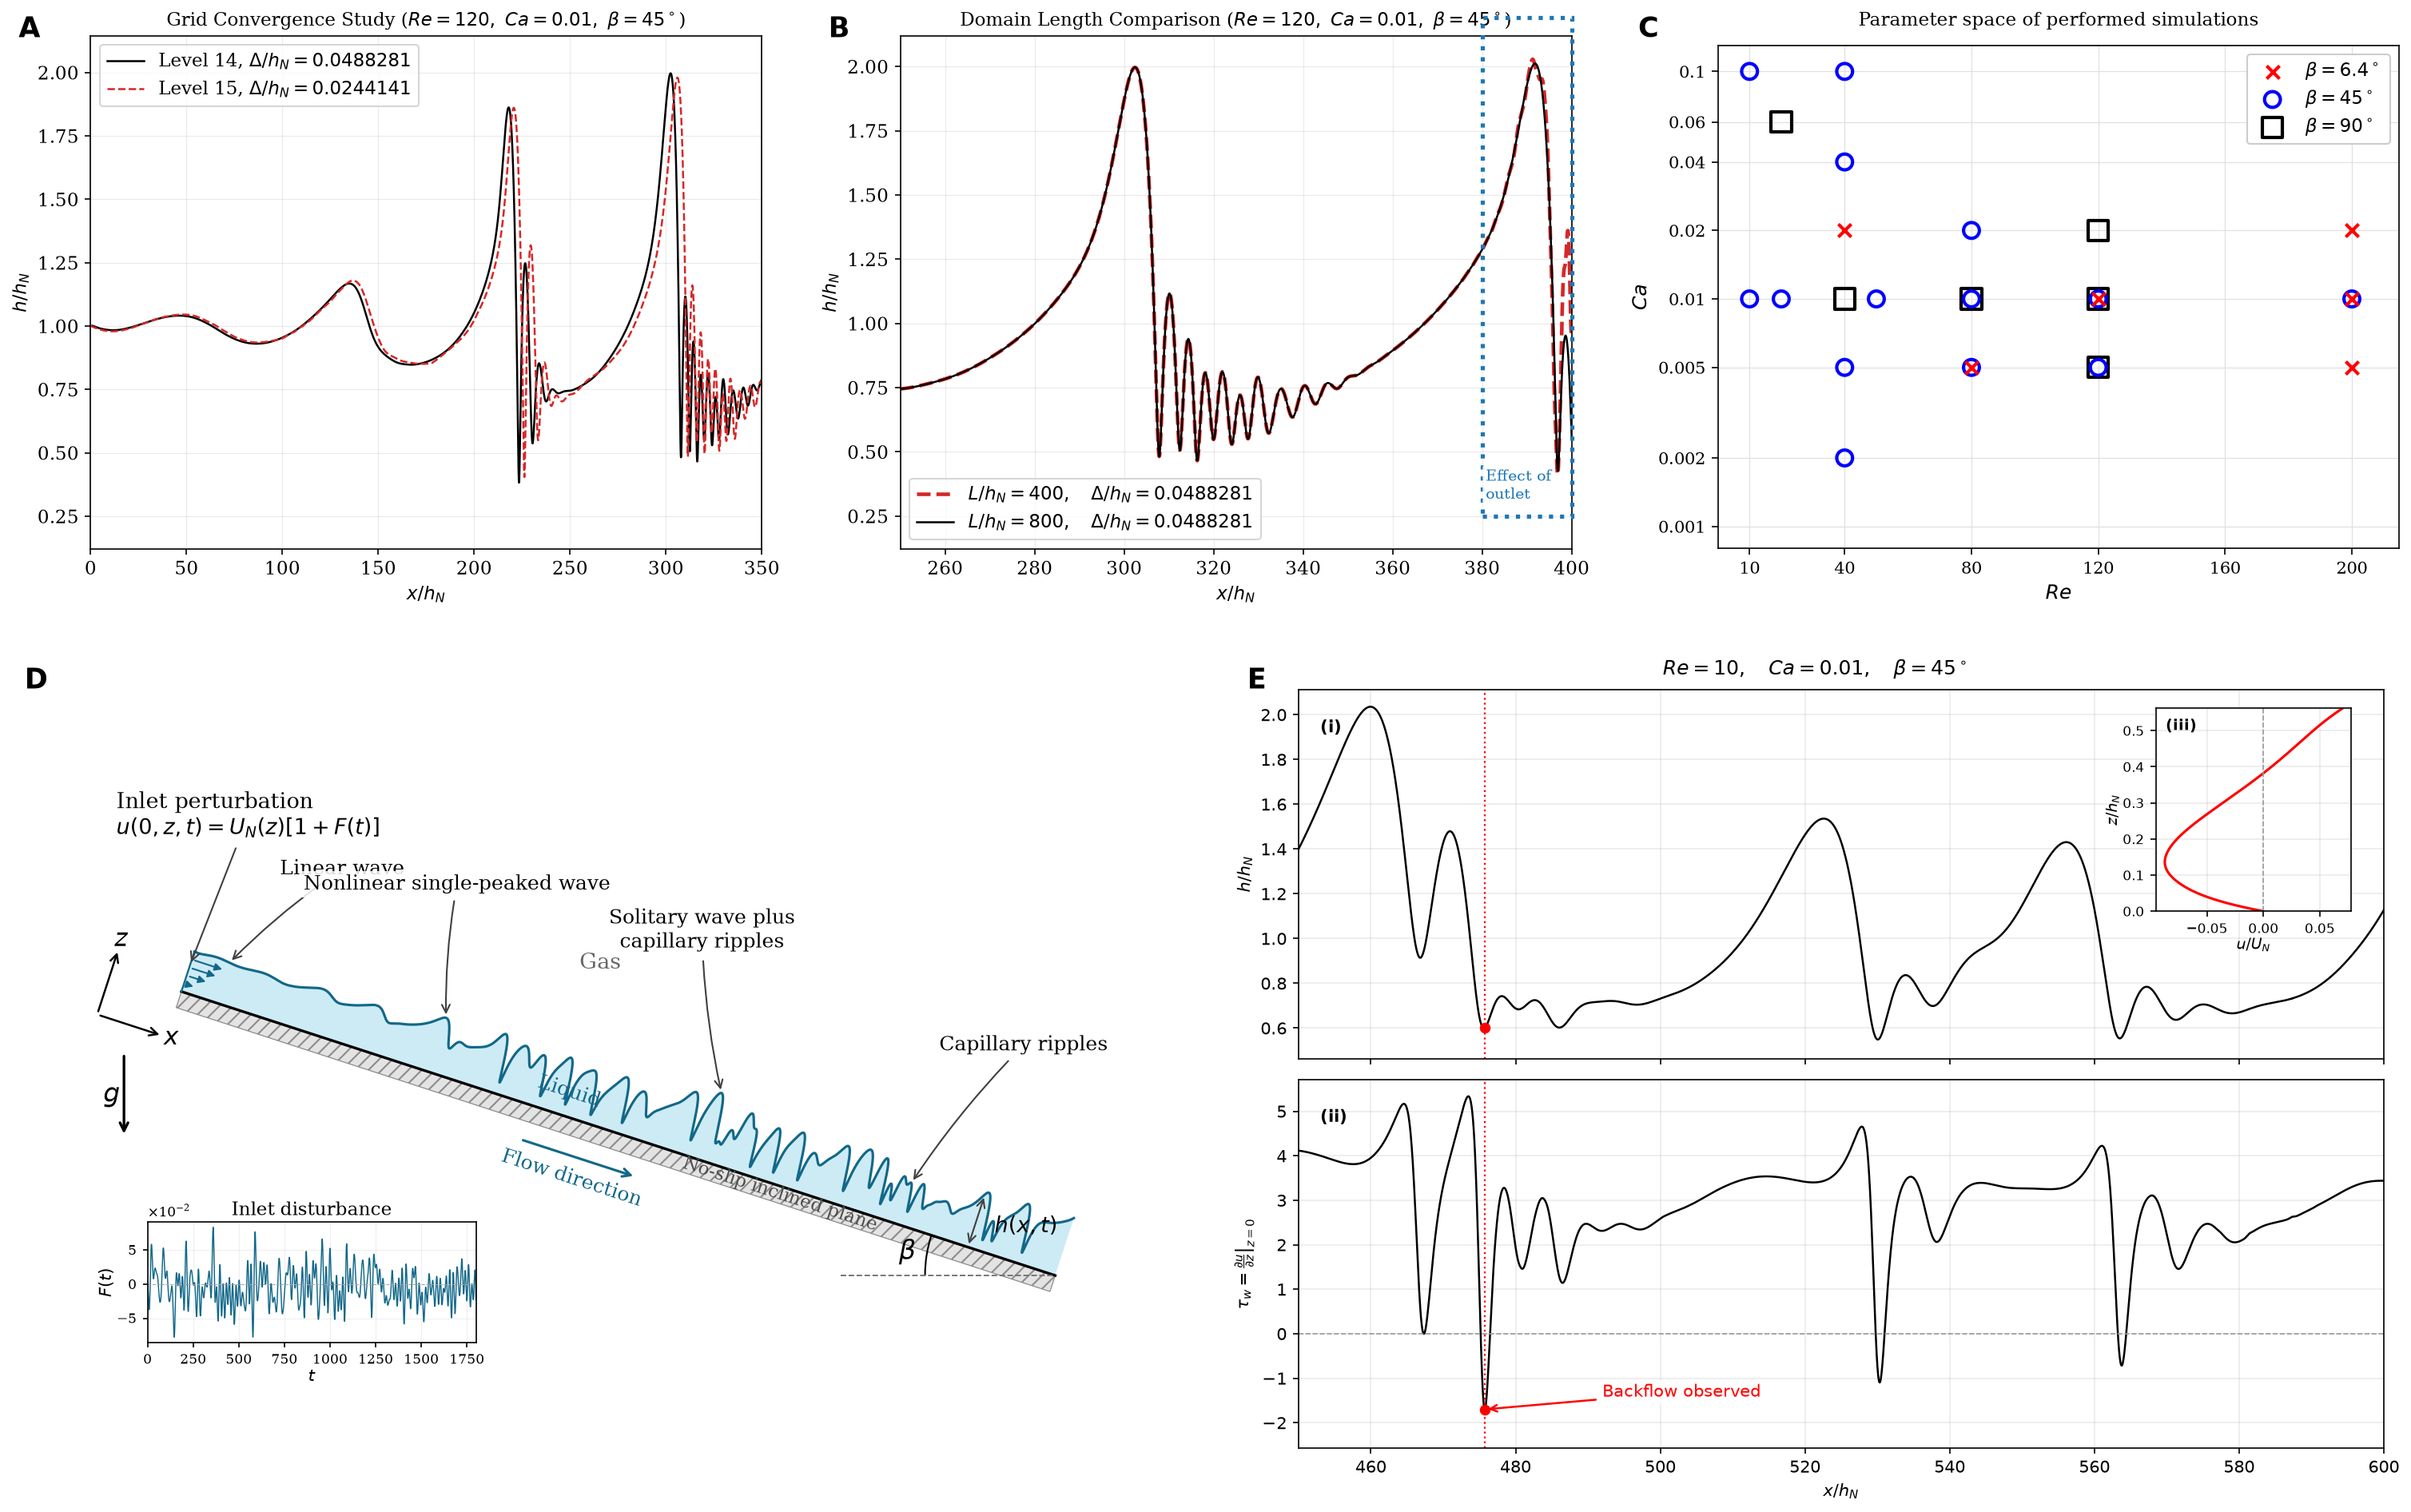

In [11]:
# Top row: A grid convergence, B domain length, C parameter space.
# Bottom row: D falling-film schematic, E backflow with (i)–(iii).
combined_figure = plt.figure(figsize=(20, 12.5), dpi=150, layout="constrained")
report_rows = combined_figure.subfigures(2, 1, height_ratios=(0.85, 1.2), hspace=0.06)
top_panels = report_rows[0].subfigures(1, 3, wspace=0.04)
bottom_panels = report_rows[1].subfigures(1, 2, wspace=0.04)
import csv
import re

MIN_H5_FILES = 100
counts_path = DATA_DIR.parent / "simulation_file_counts.csv"
case_counts = {}
pattern = re.compile(r"Re(?P<Re>\d+)_Ca(?P<Ca>\d+_\d+)_theta(?P<beta>\d+(?:_\d+)?)")
with counts_path.open(newline="") as stream:
    for row in csv.DictReader(stream):
        match = pattern.fullmatch(row["simulation_directory"])
        if match is None:
            raise ValueError(f"Unrecognized simulation name: {row['simulation_directory']}")
        case_re = int(match["Re"])
        case_ca = float(match["Ca"].replace("_", "."))
        case_beta = float(match["beta"].replace("_", "."))
        key = (case_re, case_ca, case_beta)
        if key in case_counts:
            raise ValueError(f"Duplicate simulation: {key}")
        case_counts[key] = int(row["num_h5_files"])

re_values = sorted({key[0] for key in case_counts})
ca_values = sorted({key[1] for key in case_counts})
beta_values = sorted({key[2] for key in case_counts})
assert len(beta_values) == 3, "Expected three inclination angles."

# Plot only simulations meeting the availability criterion above.
with plt.rc_context({
    "font.family": "serif", "font.size": 11,
    "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.linewidth": 0.8, "pdf.fonttype": 42,
}):
    fig_available = top_panels[2]
    ax = fig_available.subplots()
    marker_styles = [("x", "red"), ("o", "blue"), ("s", "black")]
    # Draw larger open squares first so coincident parameter sets remain visible.
    for index in (2, 1, 0):
        case_beta = beta_values[index]
        marker, color = marker_styles[index]
        performed = [(case_re, case_ca)
                     for (case_re, case_ca, angle), count in case_counts.items()
                     if angle == case_beta and count >= MIN_H5_FILES]
        re_plot, ca_plot = np.asarray(performed, dtype=float).T
        style = dict(marker=marker, label=rf"$\beta = {case_beta:g}^\circ$", zorder=3)
        if marker == "x":
            ax.scatter(re_plot, ca_plot, s=60, color=color, linewidths=2.0, **style)
        else:
            ax.scatter(re_plot, ca_plot, s=90 if marker == "o" else 150,
                       facecolors="none", edgecolors=color, linewidths=2.0, **style)
    ax.set_yscale("log")
    ax.set_xlim(0, 215)
    ax.set_ylim(0.0008, 0.13)
    ax.set_xticks([10, 40, 80, 120, 160, 200])
    ax.set_yticks(ca_values, labels=[f"{value:g}" for value in ca_values])
    ax.minorticks_off()
    ax.grid(color="0.88", linewidth=0.6, zorder=0)
    ax.tick_params(direction="out", length=4, width=0.8)
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.set_xlabel(r"$Re$")
    ax.set_ylabel(r"$Ca$")
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="upper right", frameon=True,
              facecolor="white", framealpha=1, edgecolor="0.8")
    output_dir = Path("techreport_figures")
    output_dir.mkdir(parents=True, exist_ok=True)
    availability_pdf = output_dir / "simulation_availability.pdf"
ax.set_title("Parameter space of performed simulations", pad=12)

GRID_ROOT = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/basilisk/physics-tests/bc-blowup-fix/length-check"
)
GRID_TIME = 500.0
GRID_X_LIMITS = (0, 350)
grid_cases = [("L800", "black", "-"), ("L800_Level15", "tab:red", "--")]
grid_profiles = []
for case_name, color, linestyle in grid_cases:
    case_path = GRID_ROOT / case_name
    config = {}
    for line in (case_path / "params.in").read_text().splitlines():
        if "=" in line:
            key, value = line.split("=", 1)
            config[key.strip()] = float(value.split("#")[0].strip())
    np.testing.assert_allclose(
        [config["RE"], config["CA"], config["ANGLE_DEG"], config["LX"]],
        [120, 0.01, 45, 800],
    )
    snapshot_path = case_path / "output" / f"snapshot_{GRID_TIME:06.0f}.h5"
    with h5py.File(snapshot_path, "r") as snapshot:
        np.testing.assert_allclose(float(snapshot["Parameters/time"][()]), GRID_TIME)
        np.testing.assert_allclose(
            [float(snapshot["Parameters/Re"][()]), float(snapshot["Parameters/Ca"][()]),
             np.rad2deg(float(snapshot["Parameters/angle"][()]))],
            [120, 0.01, 45],
        )
        points = snapshot["Geometry/Points"][:, :2]
        topology = snapshot["Topology"][:]
        fraction = np.asarray(snapshot["Cells/f"][:], dtype=float).reshape(-1)
    centers_x = np.zeros(topology.shape[0])
    z_lower = np.full(topology.shape[0], np.inf)
    z_upper = np.full(topology.shape[0], -np.inf)
    for corner in range(topology.shape[1]):
        vertices = points[topology[:, corner]]
        centers_x += vertices[:, 0] / topology.shape[1]
        z_lower = np.minimum(z_lower, vertices[:, 1])
        z_upper = np.maximum(z_upper, vertices[:, 1])
    cell_dz = z_upper - z_lower
    if (not np.all(np.isfinite(fraction)) or np.any(fraction < -1e-10)
            or np.any(fraction > 1 + 1e-10) or np.any(cell_dz <= 0)):
        raise ValueError(f"Invalid volume fractions or cell geometry: {case_name}")
    x_grid, columns = np.unique(np.round(centers_x, 12), return_inverse=True)
    # Finite-volume depth integral, including the liquid part of mixed cells.
    h_grid = np.bincount(columns, weights=fraction * cell_dz)
    level = int(config["MAXLEVEL"])
    spacing = config["LX"] / 2**level
    np.testing.assert_allclose(np.diff(x_grid), spacing, rtol=1e-8, atol=1e-10)
    label = rf"Level {level}, $\Delta/h_N = {spacing:.7f}$"
    grid_profiles.append((x_grid, h_grid, color, linestyle, label))
    print(f"{case_name}: t={GRID_TIME:g}; {x_grid.size:,} columns; Δ/h_N={spacing:.8g}")
    del points, topology, fraction, centers_x, z_lower, z_upper, cell_dz, columns, vertices

with plt.rc_context({"font.family": "serif", "font.size": 11, "pdf.fonttype": 42}):
    fig_grid = top_panels[0]
    ax_grid = fig_grid.subplots()
    for x_grid, h_grid, color, linestyle, label in grid_profiles:
        ax_grid.plot(x_grid, h_grid, color=color, linestyle=linestyle,
                     linewidth=1.2, label=label)
    ax_grid.set_xlim(*GRID_X_LIMITS)
    ax_grid.set_xlabel(r"$x/h_N$")
    ax_grid.set_ylabel(r"$h/h_N$")
    ax_grid.set_title(r"Grid Convergence Study ($Re=120,\ Ca=0.01,\ \beta=45^\circ$)")
    ax_grid.grid(alpha=0.25, linewidth=0.6)
    ax_grid.legend(frameon=True)
    figure_dir = Path("techreport_figures")
    figure_dir.mkdir(parents=True, exist_ok=True)
GRID_ROOT = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/basilisk/physics-tests/bc-blowup-fix/length-check"
)
GRID_TIME = 500.0
GRID_X_LIMITS = (250, 400)
grid_cases = [("L400", "tab:red", "--"), ("L800", "black", "-")]
grid_profiles = []
for case_name, color, linestyle in grid_cases:
    case_path = GRID_ROOT / case_name
    config = {}
    for line in (case_path / "params.in").read_text().splitlines():
        if "=" in line:
            key, value = line.split("=", 1)
            config[key.strip()] = float(value.split("#")[0].strip())
    np.testing.assert_allclose(
        [config["RE"], config["CA"], config["ANGLE_DEG"], config["LX"]],
        [120, 0.01, 45, float(case_name[1:])],
    )
    snapshot_path = case_path / "output" / f"snapshot_{GRID_TIME:06.0f}.h5"
    with h5py.File(snapshot_path, "r") as snapshot:
        np.testing.assert_allclose(float(snapshot["Parameters/time"][()]), GRID_TIME)
        np.testing.assert_allclose(
            [float(snapshot["Parameters/Re"][()]), float(snapshot["Parameters/Ca"][()]),
             np.rad2deg(float(snapshot["Parameters/angle"][()]))],
            [120, 0.01, 45],
        )
        points = snapshot["Geometry/Points"][:, :2]
        topology = snapshot["Topology"][:]
        fraction = np.asarray(snapshot["Cells/f"][:], dtype=float).reshape(-1)
    centers_x = np.zeros(topology.shape[0])
    z_lower = np.full(topology.shape[0], np.inf)
    z_upper = np.full(topology.shape[0], -np.inf)
    for corner in range(topology.shape[1]):
        vertices = points[topology[:, corner]]
        centers_x += vertices[:, 0] / topology.shape[1]
        z_lower = np.minimum(z_lower, vertices[:, 1])
        z_upper = np.maximum(z_upper, vertices[:, 1])
    cell_dz = z_upper - z_lower
    if (not np.all(np.isfinite(fraction)) or np.any(fraction < -1e-10)
            or np.any(fraction > 1 + 1e-10) or np.any(cell_dz <= 0)):
        raise ValueError(f"Invalid volume fractions or cell geometry: {case_name}")
    x_grid, columns = np.unique(np.round(centers_x, 12), return_inverse=True)
    # Finite-volume depth integral, including the liquid part of mixed cells.
    h_grid = np.bincount(columns, weights=fraction * cell_dz)
    level = int(config["MAXLEVEL"])
    spacing = config["LX"] / 2**level
    np.testing.assert_allclose(np.diff(x_grid), spacing, rtol=1e-8, atol=1e-10)
    label = rf"$L/h_N = {config['LX']:g},\quad \Delta/h_N = {spacing:.7f}$"
    grid_profiles.append((x_grid, h_grid, color, linestyle, label))
    print(f"{case_name}: t={GRID_TIME:g}; {x_grid.size:,} columns; Δ/h_N={spacing:.8g}")
    del points, topology, fraction, centers_x, z_lower, z_upper, cell_dz, columns, vertices

with plt.rc_context({"font.family": "serif", "font.size": 11, "pdf.fonttype": 42}):
    fig_grid = top_panels[1]
    ax_grid = fig_grid.subplots()
    for x_grid, h_grid, color, linestyle, label in grid_profiles:
        ax_grid.plot(x_grid, h_grid, color=color, linestyle=linestyle,
                     linewidth=2.2 if color == "tab:red" else 1.2, label=label)
    ax_grid.set_xlim(*GRID_X_LIMITS)
    ax_grid.set_xlabel(r"$x/h_N$")
    ax_grid.set_ylabel(r"$h/h_N$")
    ax_grid.set_title(r"Domain Length Comparison ($Re=120,\ Ca=0.01,\ \beta=45^\circ$)")
    # Last 5% of the shorter domain: x/h_N = 380–400.
    from matplotlib.patches import Rectangle
    outlet_start, outlet_end = 0.95 * 400, 400
    region_values = np.concatenate([
        heights[(coordinates >= outlet_start) & (coordinates <= outlet_end)]
        for coordinates, heights, *_ in grid_profiles
    ])
    lower, upper = region_values.min(), region_values.max()
    padding = max(0.1 * (upper - lower), 0.03)
    ax_grid.add_patch(Rectangle(
        (outlet_start, lower - padding), outlet_end - outlet_start,
        upper - lower + 2 * padding, fill=False, edgecolor="tab:blue",
        linewidth=2.5, linestyle=":", zorder=5, clip_on=False,
    ))
    ax_grid.text(
        outlet_start + 0.04 * (outlet_end - outlet_start), lower - 0.7 * padding,
        "Effect of\noutlet", ha="left", va="bottom", color="tab:blue",
        fontsize=9, zorder=6,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white",
                  edgecolor="none", alpha=0.9),
    )
    ax_grid.grid(alpha=0.25, linewidth=0.6)
    ax_grid.legend(frameon=True)
    figure_dir = Path("techreport_figures")
    figure_dir.mkdir(parents=True, exist_ok=True)
from scipy.interpolate import make_interp_spline

# A cubic interpolating spline provides a smooth profile through the liquid data.
z_smooth = np.linspace(z_liquid[0], z_liquid[-1], 500)
u_smooth = make_interp_spline(z_liquid, u_liquid, k=3)(z_smooth)

# 9 x 6 inches at 100 dpi gives a 900 x 600 pixel canvas.
fig = bottom_panels[1]
ax_height, ax_shear = fig.subplots(2, 1, sharex=True)
# Place the velocity profile inside the upper-right of the height panel.
ax_velocity = ax_height.inset_axes([0.79, 0.40, 0.18, 0.55])
ax_velocity.set_facecolor("white")
ax_velocity.tick_params(labelsize=8)

ax_height.plot(x, height, color="black", linewidth=1.2)
ax_height.set_ylabel(r"$h/h_N$")
ax_height.tick_params(axis="x", labelbottom=False)

ax_shear.plot(x, tau_wall, color="black", linewidth=1.2)
ax_shear.axhline(0, color="0.6", linewidth=0.8, linestyle="--")
ax_shear.set_xlabel(r"$x/h_N$")
ax_shear.set_ylabel(r"$\tau_w = \left.\frac{\partial u}{\partial z}\right|_{z=0}$")

for ax, value in ((ax_height, height[selected_index]),
                  (ax_shear, tau_wall[selected_index])):
    ax.axvline(selected_x, color="red", linestyle=":", linewidth=1.1)
    ax.scatter([selected_x], [value], color="red", s=30, zorder=4)
    ax.set_xlim(*X_LIMITS)
    ax.grid(alpha=0.25)

ax_velocity.plot(u_smooth, z_smooth, color="red", linewidth=1.5)
ax_velocity.axvline(0, color="0.6", linewidth=0.8, linestyle="--")
ax_velocity.set_xlabel(r"$u/U_N$", fontsize=9, labelpad=1)
ax_velocity.set_ylabel(r"$z/h_N$", fontsize=9, labelpad=1)
ax_velocity.set_ylim(z_smooth[0], z_smooth[-1])
ax_velocity.grid(alpha=0.25)

fig.suptitle(rf"$Re = {RE},\quad Ca = {CA:g},\quad \beta = {THETA}^\circ$")
output_dir = Path("techreport_figures")
output_dir.mkdir(parents=True, exist_ok=True)
pdf_path = output_dir / "section1_backflow.pdf"
print(f"Saved: {pdf_path.resolve()}")
ax_height.text(0.02, 0.92, "(i)", transform=ax_height.transAxes, va="top", fontweight="bold")
ax_shear.text(0.02, 0.92, "(ii)", transform=ax_shear.transAxes, va="top", fontweight="bold")
ax_velocity.text(0.05, 0.95, "(iii)", transform=ax_velocity.transAxes, va="top", fontsize=9, fontweight="bold")
ax_shear.annotate(
    "Backflow observed", xy=(selected_x, tau_wall[selected_index]),
    xytext=(0.28, 0.14), textcoords="axes fraction",
    color="red", fontsize=10,
    arrowprops=dict(arrowstyle="->", color="red", linewidth=1.2),
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2),
)


from matplotlib.patches import Polygon, Arc, FancyArrowPatch

schematic_file = DATA_DIR / "thinfilm_closure_data_Re120_Ca0_010_theta45.h5"
with h5py.File(schematic_file, "r") as schematic_data:
    schematic_x = np.asarray(schematic_data["x"][:]).reshape(-1)
    schematic_times = np.asarray(schematic_data["t"][:]).reshape(-1)
    schematic_it = int(np.argmin(np.abs(schematic_times - 1800.0)))
    np.testing.assert_allclose(schematic_times[schematic_it], 1800.0)
    field = schematic_data["h"]
    schematic_h = np.asarray(field[:, schematic_it] if field.shape ==
                             (schematic_x.size, schematic_times.size)
                             else field[schematic_it, :])

# Retain only x/h_N = 0–500 from the source profile.
SCHEMATIC_X_MAX = 500.0
visible = schematic_x < SCHEMATIC_X_MAX
end_height = float(np.interp(SCHEMATIC_X_MAX, schematic_x, schematic_h))
schematic_x = np.r_[schematic_x[visible], SCHEMATIC_X_MAX]
schematic_h = np.r_[schematic_h[visible], end_height]
wave_region = np.flatnonzero((schematic_x >= 250) & (schematic_x <= 300))
nonlinear_wave_x = float(schematic_x[wave_region[np.argmax(schematic_h[wave_region])]])

# Map downstream distance and exaggerated height onto an inclined plane.
# The display angle is illustrative; beta denotes the physical inclination.
display_angle = np.deg2rad(18)
plane_tangent = np.array([np.cos(display_angle), -np.sin(display_angle)])
plane_normal = np.array([np.sin(display_angle), np.cos(display_angle)])
plane_origin = np.array([1.2, 5.4])
length_scale, thickness_scale = 12.0 / SCHEMATIC_X_MAX, 0.55

def film_point(distance, thickness=0.0):
    return (plane_origin + np.asarray(distance)[..., None] * length_scale * plane_tangent
            + np.asarray(thickness)[..., None] * thickness_scale * plane_normal)

def surface_point(distance):
    index = int(np.argmin(np.abs(schematic_x - distance)))
    return film_point(schematic_x[index], schematic_h[index])

# Read the measured inlet disturbance F(t), using the file's named columns.
signal_path = DATA_DIR.parent / "Re120_Ca0_010_theta45" / "inlet_signal.dat"
inlet_history = np.loadtxt(signal_path, usecols=(0, 1))
valid_history = np.all(np.isfinite(inlet_history), axis=1)
valid_history &= (inlet_history[:, 0] >= 0) & (inlet_history[:, 0] <= 1800)
inlet_history = inlet_history[valid_history]
if inlet_history.shape[0] < 2:
    raise ValueError("Insufficient inlet disturbance data.")
# Select a uniformly spaced display sample; retain the original signal values.
inlet_display_indices = np.unique(np.linspace(0, len(inlet_history) - 1,
                                              min(12000, len(inlet_history))).astype(int))

with plt.rc_context({"font.family": "serif", "font.size": 12, "pdf.fonttype": 42}):
    fig_schematic = bottom_panels[0]
    # Reserve a narrow left gutter to shift the schematic right within its panel.
    schematic_layout = fig_schematic.add_gridspec(1, 2, width_ratios=(0.06, 0.94), wspace=0)
    ax_schematic = fig_schematic.add_subplot(schematic_layout[0, 1])
    surface = film_point(schematic_x, schematic_h)
    wall_start, wall_end = film_point(0), film_point(SCHEMATIC_X_MAX)
    liquid_polygon = np.vstack([wall_start, surface, wall_end])
    ax_schematic.add_patch(Polygon(liquid_polygon, facecolor="#cdebf5", edgecolor="none"))
    ax_schematic.add_patch(Polygon(
        [wall_start, wall_end, wall_end - 0.22 * plane_normal,
         wall_start - 0.22 * plane_normal],
        facecolor="#e3e3e3", edgecolor="0.55", hatch="///", linewidth=0.6,
    ))
    ax_schematic.plot(surface[:, 0], surface[:, 1], color="#126889", linewidth=1.5)
    ax_schematic.plot([wall_start[0], wall_end[0]], [wall_start[1], wall_end[1]],
                      color="black", linewidth=1.6)
    ax_schematic.plot([wall_start[0], surface[0, 0]], [wall_start[1], surface[0, 1]],
                      color="#126889", linewidth=1.1)

    # Inlet velocity arrows follow a Nusselt-type parabolic profile.
    for normalized_z in [0.2, 0.4, 0.6, 0.8]:
        start = film_point(0, normalized_z)
        speed = 0.48 * (2 * normalized_z - normalized_z**2)
        end = start + speed * plane_tangent
        ax_schematic.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>",
                                               mutation_scale=9, color="#126889", linewidth=1))
    ax_schematic.annotate(
        r"Inlet perturbation" + "\n" + r"$u(0,z,t)=U_N(z)\left[1+F(t)\right]$",
        xy=film_point(0, 0.65), xytext=(0.35, 7.7),
        ha="left", va="center", fontsize=13,
        arrowprops=dict(arrowstyle="->", color="0.25", linewidth=1),
    )

    # Representative morphological features in the actual source profile.
    feature_labels = [
        (20, "Linear wave", (3.3, 7.0)),
        (141.382, "Nonlinear single-peaked wave", (4.8, 6.8)),
        (nonlinear_wave_x, "Solitary wave plus\ncapillary ripples", (8.0, 6.2)),
        (410, "Capillary ripples", (12.2, 4.7)),
    ]
    for location, text, label_position in feature_labels:
        ax_schematic.annotate(
            text, xy=surface_point(location), xytext=label_position,
            ha="center", va="center", fontsize=12,
            arrowprops=dict(arrowstyle="->", color="0.25", linewidth=1,
                            connectionstyle="arc3,rad=0.05"),
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2),
        )

    # Inclination at the lower-right end, between the plane and a horizontal.
    ax_schematic.plot([wall_end[0] - 2.8, wall_end[0]],
                      [wall_end[1], wall_end[1]], color="0.45", linestyle="--", linewidth=0.9)
    ax_schematic.add_patch(Arc(wall_end, 3.4, 3.4, theta1=162, theta2=180,
                               color="black", linewidth=1))
    beta_label = wall_end + 1.95 * np.array([-np.cos(display_angle / 2), np.sin(display_angle / 2)])
    ax_schematic.text(*beta_label, r"$\beta$", fontsize=16, ha="center", va="center")

    # Coordinates, flow direction, thickness and gravity.
    coordinate_origin = np.array([0.1, 5.1])  # White space beside the inlet.
    for direction, label in [(plane_tangent, r"$x$"), (plane_normal, r"$z$")]:
        tip = coordinate_origin + 0.9 * direction
        ax_schematic.annotate("", xy=tip, xytext=coordinate_origin,
                              arrowprops=dict(arrowstyle="->", linewidth=1.2, color="black"))
        ax_schematic.text(*(tip + 0.12 * direction), label, fontsize=15, ha="center", va="center")
    flow_start = film_point(200, -0.85)
    flow_end = flow_start + 1.6 * plane_tangent
    ax_schematic.annotate("", xy=flow_end, xytext=flow_start,
                          arrowprops=dict(arrowstyle="->", linewidth=1.5, color="#126889"))
    ax_schematic.text(*(0.5 * (flow_start + flow_end) - 0.28 * plane_normal),
                      "Flow direction", rotation=-18, ha="center", va="center", color="#126889")
    thickness_x = 450
    thickness_h = float(np.interp(thickness_x, schematic_x, schematic_h))
    ax_schematic.annotate("", xy=film_point(thickness_x, thickness_h),
                          xytext=film_point(thickness_x),
                          arrowprops=dict(arrowstyle="<->", color="0.25", linewidth=1))
    ax_schematic.text(*(film_point(thickness_x, 0.5 * thickness_h) + 0.25 * plane_tangent),
                      r"$h(x,t)$", fontsize=13, ha="left", va="center")
    ax_schematic.annotate("", xy=(0.45, 3.5), xytext=(0.45, 4.6),
                          arrowprops=dict(arrowstyle="->", color="black", linewidth=1.6))
    ax_schematic.text(0.18, 4.05, r"$g$", fontsize=16, va="center")
    ax_schematic.text(6.4, 5.7, "Gas", color="0.4", fontsize=13)
    ax_schematic.text(*film_point(220, 0.25), "Liquid", color="#126889",
                      fontsize=12, rotation=-18, ha="center")
    ax_schematic.text(*film_point(350, -1.0), "No-slip inclined plane", color="0.3",
                      rotation=-18, ha="center", fontsize=11)
    ax_schematic.set_aspect("equal")
    ax_schematic.set_xlim(-0.1, 14.2)
    ax_schematic.set_ylim(0.3, 8.2)
    ax_schematic.axis("off")
    inlet_ax = ax_schematic.inset_axes([0.06, 0.065, 0.30, 0.20])
    inlet_ax.plot(inlet_history[inlet_display_indices, 0],
                  inlet_history[inlet_display_indices, 1],
                  color="#126889", linewidth=0.7)
    inlet_ax.axhline(0, color="0.65", linewidth=0.5, linestyle="--")
    inlet_ax.set_xlim(0, 1800)
    inlet_ax.set_xlabel(r"$t$", fontsize=10, labelpad=1)
    inlet_ax.set_ylabel(r"$F(t)$", fontsize=10, labelpad=1)
    inlet_ax.set_title("Inlet disturbance", fontsize=11, pad=4)
    inlet_ax.tick_params(labelsize=8, direction="out", length=3)
    inlet_ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2), useMathText=True)
    inlet_ax.yaxis.get_offset_text().set_fontsize(8)
    inlet_ax.grid(alpha=0.2, linewidth=0.5)

    schematic_dir = Path("techreport_figures")
    schematic_dir.mkdir(parents=True, exist_ok=True)
for panel in top_panels:
    for panel_ax in panel.axes:
        panel_ax.title.set_fontsize(11)
for panel, letter in zip([*top_panels, *bottom_panels], "ABCDE"):
    panel.text(0.015, 0.985, letter, ha="left", va="top", fontsize=17, fontweight="bold")
combined_path = Path("techreport_figures/combined_report_figures.pdf")
combined_path.parent.mkdir(parents=True, exist_ok=True)
combined_figure.savefig(combined_path, format="pdf")
plt.show()


## Falling-film schematic

Free-surface prototype: `thinfilm_closure_data_Re120_Ca0_010_theta45.h5`, t = 1800. The film thickness and plane inclination are drawn schematically for readability; the source simulation has β = 45°. Wave annotations describe representative shapes in the profile, rather than a quantitative stability classification. The wall-normal direction is $z$ and the downstream direction is $x$.

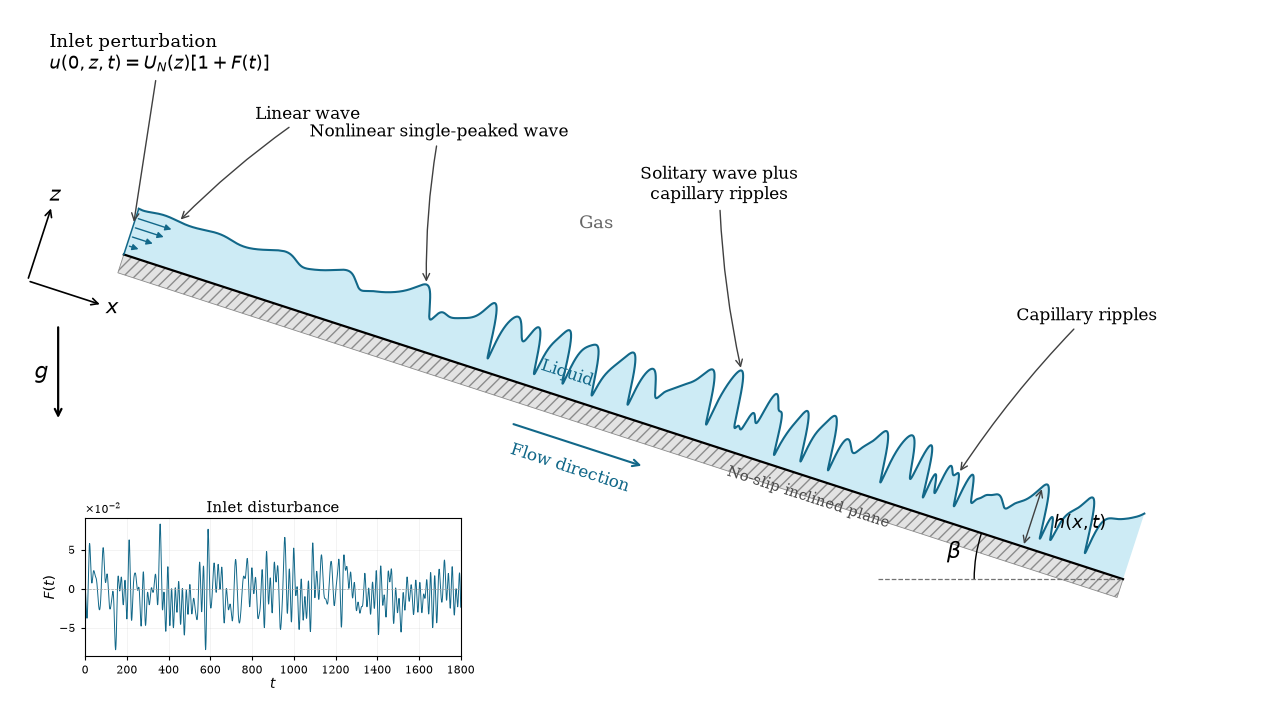

In [12]:
from matplotlib.patches import Polygon, Arc, FancyArrowPatch

schematic_file = DATA_DIR / "thinfilm_closure_data_Re120_Ca0_010_theta45.h5"
with h5py.File(schematic_file, "r") as schematic_data:
    schematic_x = np.asarray(schematic_data["x"][:]).reshape(-1)
    schematic_times = np.asarray(schematic_data["t"][:]).reshape(-1)
    schematic_it = int(np.argmin(np.abs(schematic_times - 1800.0)))
    np.testing.assert_allclose(schematic_times[schematic_it], 1800.0)
    field = schematic_data["h"]
    schematic_h = np.asarray(field[:, schematic_it] if field.shape ==
                             (schematic_x.size, schematic_times.size)
                             else field[schematic_it, :])

# Retain only x/h_N = 0–500 from the source profile.
SCHEMATIC_X_MAX = 500.0
visible = schematic_x < SCHEMATIC_X_MAX
end_height = float(np.interp(SCHEMATIC_X_MAX, schematic_x, schematic_h))
schematic_x = np.r_[schematic_x[visible], SCHEMATIC_X_MAX]
schematic_h = np.r_[schematic_h[visible], end_height]
wave_region = np.flatnonzero((schematic_x >= 250) & (schematic_x <= 300))
nonlinear_wave_x = float(schematic_x[wave_region[np.argmax(schematic_h[wave_region])]])

# Map downstream distance and exaggerated height onto an inclined plane.
# The display angle is illustrative; beta denotes the physical inclination.
display_angle = np.deg2rad(18)
plane_tangent = np.array([np.cos(display_angle), -np.sin(display_angle)])
plane_normal = np.array([np.sin(display_angle), np.cos(display_angle)])
plane_origin = np.array([1.2, 5.4])
length_scale, thickness_scale = 12.0 / SCHEMATIC_X_MAX, 0.55

def film_point(distance, thickness=0.0):
    return (plane_origin + np.asarray(distance)[..., None] * length_scale * plane_tangent
            + np.asarray(thickness)[..., None] * thickness_scale * plane_normal)

def surface_point(distance):
    index = int(np.argmin(np.abs(schematic_x - distance)))
    return film_point(schematic_x[index], schematic_h[index])

# Read the measured inlet disturbance F(t), using the file's named columns.
signal_path = DATA_DIR.parent / "Re120_Ca0_010_theta45" / "inlet_signal.dat"
inlet_history = np.loadtxt(signal_path, usecols=(0, 1))
valid_history = np.all(np.isfinite(inlet_history), axis=1)
valid_history &= (inlet_history[:, 0] >= 0) & (inlet_history[:, 0] <= 1800)
inlet_history = inlet_history[valid_history]
if inlet_history.shape[0] < 2:
    raise ValueError("Insufficient inlet disturbance data.")
# Select a uniformly spaced display sample; retain the original signal values.
inlet_display_indices = np.unique(np.linspace(0, len(inlet_history) - 1,
                                              min(12000, len(inlet_history))).astype(int))

with plt.rc_context({"font.family": "serif", "font.size": 12, "pdf.fonttype": 42}):
    fig_schematic, ax_schematic = plt.subplots(figsize=(14, 7), layout="constrained")
    surface = film_point(schematic_x, schematic_h)
    wall_start, wall_end = film_point(0), film_point(SCHEMATIC_X_MAX)
    liquid_polygon = np.vstack([wall_start, surface, wall_end])
    ax_schematic.add_patch(Polygon(liquid_polygon, facecolor="#cdebf5", edgecolor="none"))
    ax_schematic.add_patch(Polygon(
        [wall_start, wall_end, wall_end - 0.22 * plane_normal,
         wall_start - 0.22 * plane_normal],
        facecolor="#e3e3e3", edgecolor="0.55", hatch="///", linewidth=0.6,
    ))
    ax_schematic.plot(surface[:, 0], surface[:, 1], color="#126889", linewidth=1.5)
    ax_schematic.plot([wall_start[0], wall_end[0]], [wall_start[1], wall_end[1]],
                      color="black", linewidth=1.6)
    ax_schematic.plot([wall_start[0], surface[0, 0]], [wall_start[1], surface[0, 1]],
                      color="#126889", linewidth=1.1)

    # Inlet velocity arrows follow a Nusselt-type parabolic profile.
    for normalized_z in [0.2, 0.4, 0.6, 0.8]:
        start = film_point(0, normalized_z)
        speed = 0.48 * (2 * normalized_z - normalized_z**2)
        end = start + speed * plane_tangent
        ax_schematic.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>",
                                               mutation_scale=9, color="#126889", linewidth=1))
    ax_schematic.annotate(
        r"Inlet perturbation" + "\n" + r"$u(0,z,t)=U_N(z)\left[1+F(t)\right]$",
        xy=film_point(0, 0.65), xytext=(0.35, 7.7),
        ha="left", va="center", fontsize=13,
        arrowprops=dict(arrowstyle="->", color="0.25", linewidth=1),
    )

    # Representative morphological features in the actual source profile.
    feature_labels = [
        (20, "Linear wave", (3.3, 7.0)),
        (141.382, "Nonlinear single-peaked wave", (4.8, 6.8)),
        (nonlinear_wave_x, "Solitary wave plus\ncapillary ripples", (8.0, 6.2)),
        (410, "Capillary ripples", (12.2, 4.7)),
    ]
    for location, text, label_position in feature_labels:
        ax_schematic.annotate(
            text, xy=surface_point(location), xytext=label_position,
            ha="center", va="center", fontsize=12,
            arrowprops=dict(arrowstyle="->", color="0.25", linewidth=1,
                            connectionstyle="arc3,rad=0.05"),
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2),
        )

    # Inclination at the lower-right end, between the plane and a horizontal.
    ax_schematic.plot([wall_end[0] - 2.8, wall_end[0]],
                      [wall_end[1], wall_end[1]], color="0.45", linestyle="--", linewidth=0.9)
    ax_schematic.add_patch(Arc(wall_end, 3.4, 3.4, theta1=162, theta2=180,
                               color="black", linewidth=1))
    beta_label = wall_end + 1.95 * np.array([-np.cos(display_angle / 2), np.sin(display_angle / 2)])
    ax_schematic.text(*beta_label, r"$\beta$", fontsize=16, ha="center", va="center")

    # Coordinates, flow direction, thickness and gravity.
    coordinate_origin = np.array([0.1, 5.1])  # White space beside the inlet.
    for direction, label in [(plane_tangent, r"$x$"), (plane_normal, r"$z$")]:
        tip = coordinate_origin + 0.9 * direction
        ax_schematic.annotate("", xy=tip, xytext=coordinate_origin,
                              arrowprops=dict(arrowstyle="->", linewidth=1.2, color="black"))
        ax_schematic.text(*(tip + 0.12 * direction), label, fontsize=15, ha="center", va="center")
    flow_start = film_point(200, -0.85)
    flow_end = flow_start + 1.6 * plane_tangent
    ax_schematic.annotate("", xy=flow_end, xytext=flow_start,
                          arrowprops=dict(arrowstyle="->", linewidth=1.5, color="#126889"))
    ax_schematic.text(*(0.5 * (flow_start + flow_end) - 0.28 * plane_normal),
                      "Flow direction", rotation=-18, ha="center", va="center", color="#126889")
    thickness_x = 450
    thickness_h = float(np.interp(thickness_x, schematic_x, schematic_h))
    ax_schematic.annotate("", xy=film_point(thickness_x, thickness_h),
                          xytext=film_point(thickness_x),
                          arrowprops=dict(arrowstyle="<->", color="0.25", linewidth=1))
    ax_schematic.text(*(film_point(thickness_x, 0.5 * thickness_h) + 0.25 * plane_tangent),
                      r"$h(x,t)$", fontsize=13, ha="left", va="center")
    ax_schematic.annotate("", xy=(0.45, 3.5), xytext=(0.45, 4.6),
                          arrowprops=dict(arrowstyle="->", color="black", linewidth=1.6))
    ax_schematic.text(0.18, 4.05, r"$g$", fontsize=16, va="center")
    ax_schematic.text(6.4, 5.7, "Gas", color="0.4", fontsize=13)
    ax_schematic.text(*film_point(220, 0.25), "Liquid", color="#126889",
                      fontsize=12, rotation=-18, ha="center")
    ax_schematic.text(*film_point(350, -1.0), "No-slip inclined plane", color="0.3",
                      rotation=-18, ha="center", fontsize=11)
    ax_schematic.set_aspect("equal")
    ax_schematic.set_xlim(-0.1, 14.2)
    ax_schematic.set_ylim(0.3, 8.2)
    ax_schematic.axis("off")
    inlet_ax = ax_schematic.inset_axes([0.06, 0.065, 0.30, 0.20])
    inlet_ax.plot(inlet_history[inlet_display_indices, 0],
                  inlet_history[inlet_display_indices, 1],
                  color="#126889", linewidth=0.7)
    inlet_ax.axhline(0, color="0.65", linewidth=0.5, linestyle="--")
    inlet_ax.set_xlim(0, 1800)
    inlet_ax.set_xlabel(r"$t$", fontsize=10, labelpad=1)
    inlet_ax.set_ylabel(r"$F(t)$", fontsize=10, labelpad=1)
    inlet_ax.set_title("Inlet disturbance", fontsize=11, pad=4)
    inlet_ax.tick_params(labelsize=8, direction="out", length=3)
    inlet_ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2), useMathText=True)
    inlet_ax.yaxis.get_offset_text().set_fontsize(8)
    inlet_ax.grid(alpha=0.2, linewidth=0.5)

    schematic_dir = Path("techreport_figures")
    schematic_dir.mkdir(parents=True, exist_ok=True)
    fig_schematic.savefig(schematic_dir / "falling_film_schematic.pdf", format="pdf")
    fig_schematic.savefig(schematic_dir / "falling_film_schematic.svg", format="svg")
    plt.show()


## Section 2: DNS L800 versus ROM

Compare at nondimensional t = 460, available in both simulations when this figure was prepared. DNS film height is the liquid volume-fraction depth integral from the L800 output snapshot; ROM film height is read directly from its solver output. No phase alignment or smoothing is applied.

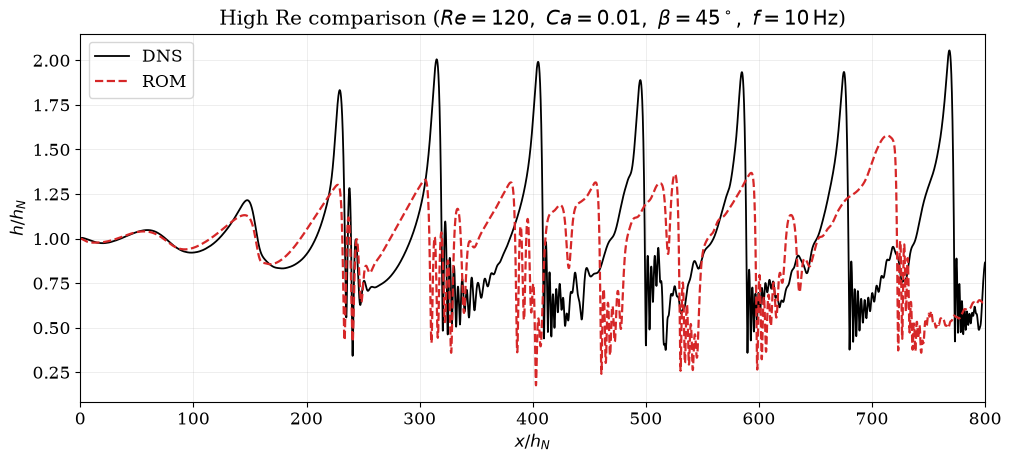

Comparison at t=460: DNS 16,384 cells, ROM 4,000 cells.


In [1]:
# Self-contained data loading for the section 2 comparison.
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

COMPARISON_TIME = 460.0
project_root = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml")
dns_case = project_root / "codes/basilisk/physics-tests/bc-blowup-fix/length-check/L800"
rom_case = project_root / "codes/rom-solver/inclined-frequency/cases/Re120_Ca0_010_beta45_f10Hz_L800_N4000"
with h5py.File(rom_case / "thinfilm_training_data.h5", "r") as rom_file:
    rom_x = np.asarray(rom_file["x"][:]).reshape(-1)
    rom_times = np.asarray(rom_file["time"][:]).reshape(-1)
    matches = np.flatnonzero(np.isclose(rom_times, COMPARISON_TIME, rtol=0, atol=1e-8))
    if matches.size != 1:
        raise ValueError("Requested comparison time is not available in ROM output.")
    rom_it = int(matches[0])
    field = rom_file["h"]
    if field.shape == (rom_x.size, rom_times.size):
        rom_height = np.asarray(field[:, rom_it])
    elif field.shape == (rom_times.size, rom_x.size):
        rom_height = np.asarray(field[rom_it, :])
    else:
        raise ValueError(f"Unexpected ROM height shape: {field.shape}")
    rom_parameters = {name: float(np.asarray(rom_file.attrs[name]).item())
                      for name in ["Re", "Ca", "theta_deg", "hN", "TN", "f_dim", "F0"]}
np.testing.assert_allclose([rom_parameters[k] for k in ["Re", "Ca", "theta_deg", "f_dim", "F0"]],
                           [120, 0.01, 45, 10, 0.03])

snapshot_path = dns_case / "output" / f"snapshot_{COMPARISON_TIME:06.0f}.h5"
with h5py.File(snapshot_path, "r") as dns_file:
    np.testing.assert_allclose(float(dns_file["Parameters/time"][()]), COMPARISON_TIME)
    np.testing.assert_allclose(
        [float(dns_file["Parameters/Re"][()]), float(dns_file["Parameters/Ca"][()]),
         np.rad2deg(float(dns_file["Parameters/angle"][()]))], [120, 0.01, 45])
    np.testing.assert_allclose(
        [float(dns_file["Parameters/h0"][()]), float(dns_file["Parameters/t0"][()])],
        [rom_parameters["hN"], rom_parameters["TN"]])
    mesh_points = dns_file["Geometry/Points"][:, :2]
    mesh_topology = dns_file["Topology"][:]
    fraction = np.asarray(dns_file["Cells/f"][:]).reshape(-1)
centers_x = np.zeros(mesh_topology.shape[0])
z_lower = np.full(mesh_topology.shape[0], np.inf)
z_upper = np.full(mesh_topology.shape[0], -np.inf)
for corner in range(mesh_topology.shape[1]):
    vertices = mesh_points[mesh_topology[:, corner]]
    centers_x += vertices[:, 0] / mesh_topology.shape[1]
    z_lower = np.minimum(z_lower, vertices[:, 1])
    z_upper = np.maximum(z_upper, vertices[:, 1])
dns_x, column_indices = np.unique(np.round(centers_x, 12), return_inverse=True)
dns_height = np.bincount(column_indices, weights=fraction * (z_upper - z_lower))
del mesh_points, mesh_topology, fraction, centers_x, z_lower, z_upper, vertices, column_indices
if not all(np.all(np.isfinite(a)) and np.all(a > 0) for a in [dns_height, rom_height]):
    raise ValueError("Invalid film height in comparison.")

with plt.rc_context({"font.family": "serif", "font.size": 12, "pdf.fonttype": 42}):
    fig_comparison, ax_comparison = plt.subplots(figsize=(10, 4.5), layout="constrained")
    ax_comparison.plot(dns_x, dns_height, color="black", linewidth=1.3,
                       label="DNS")
    ax_comparison.plot(rom_x, rom_height, color="tab:red", linestyle="--", linewidth=1.6,
                       label="ROM")
    ax_comparison.set_xlim(0, 800)
    ax_comparison.set_xlabel(r"$x/h_N$")
    ax_comparison.set_ylabel(r"$h/h_N$")
    ax_comparison.set_title(
        r"High Re comparison ($Re=120,\ Ca=0.01,\ \beta=45^\circ,\ f=10\,\mathrm{Hz}$)")
    ax_comparison.grid(alpha=0.25, linewidth=0.6)
    ax_comparison.legend(frameon=True)
    section2_dir = Path("section2_figures")
    section2_dir.mkdir(parents=True, exist_ok=True)
    figure_stem = section2_dir / f"L800_ROM_interface_t{COMPARISON_TIME:g}"
    fig_comparison.savefig(figure_stem.with_suffix(".pdf"), format="pdf")
    fig_comparison.savefig(figure_stem.with_suffix(".png"), dpi=300)
    plt.show()
print(f"Comparison at t={COMPARISON_TIME:g}: DNS {dns_x.size:,} cells, ROM {rom_x.size:,} cells.")


## Section 2: Liu-case DNS–ROM comparison at t = 10 s

The DNS interface coordinates and ROM `x_dim` are dimensional. ROM `hi` is already $h/h_N$, as confirmed in `thinfilm-solver/main_filmsolver.m`. Both profiles use the common saved ROM reference thickness $h_N=1.2789144$ mm (DNS input H0 = 1.279 mm). The title uses nominal Re = 19.33 and Ca = 0.01; the saved ROM values are Re = 19.3333 and Ca = We/Re ≈ 0.00953904. No phase alignment or smoothing is applied.

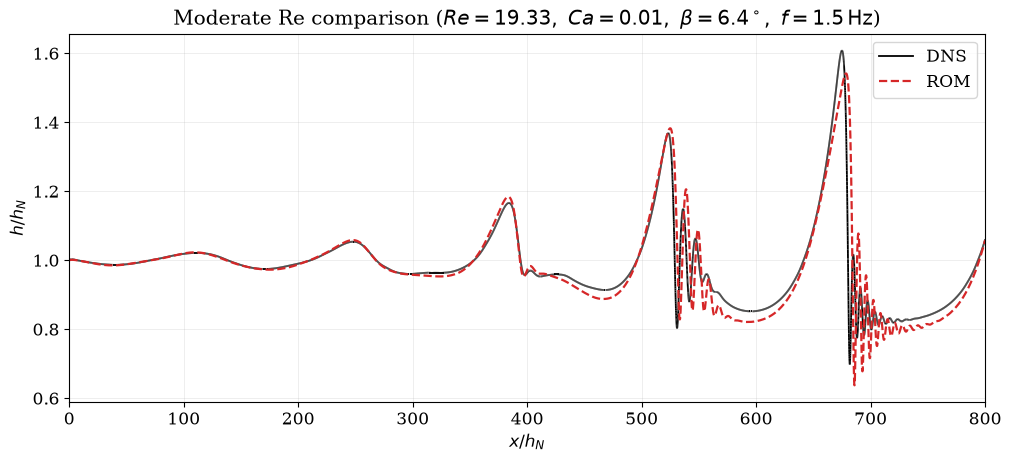

Nominal time: 10 s; common h_N: 0.001278914401 m
Saved ROM parameters: Re=19.333333, Ca=0.009539037


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

liu_dns_dir = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/Setups/basilisk/back2basics/clsvof/LX_2.0_test")
liu_rom_dir = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-solver/1.5Hz")
LIU_TIME_SECONDS = 10.0
liu_rom = loadmat(liu_rom_dir / f"Freq_1.5Hz_time_{LIU_TIME_SECONDS:.4f}s.mat")
liu_hN = float(liu_rom["hN"].item())
liu_Re = float(liu_rom["Re"].item())
liu_Ca = float(liu_rom["We"].item()) / liu_Re
liu_rom_x = np.asarray(liu_rom["x_dim"]).reshape(-1) / liu_hN
liu_rom_height = np.asarray(liu_rom["hi"]).reshape(-1)  # Already nondimensional.
np.testing.assert_allclose(liu_Re, 19.33, atol=0.005, rtol=0)
if liu_hN <= 0 or liu_rom_x.shape != liu_rom_height.shape:
    raise ValueError("Invalid ROM scale or profile dimensions.")
# Each pair of rows defines one reconstructed DNS interface segment.
liu_vertices = np.loadtxt(liu_dns_dir / f"infc{LIU_TIME_SECONDS:.4f}.dat")
if liu_vertices.ndim != 2 or liu_vertices.shape[1] != 2 or len(liu_vertices) % 2:
    raise ValueError("Unexpected DNS interface segment format.")
liu_segments = (liu_vertices / liu_hN).reshape(-1, 2, 2)
if not all(np.all(np.isfinite(a)) for a in [liu_segments, liu_rom_x, liu_rom_height]):
    raise ValueError("Nonfinite profile values.")
# Select visible segments without joining separate reconstructed facets.
liu_visible = (liu_segments[:, :, 0].max(axis=1) >= 0) & (liu_segments[:, :, 0].min(axis=1) <= 800)
liu_rom_visible = (liu_rom_x >= 0) & (liu_rom_x <= 800)
with plt.rc_context({"font.family": "serif", "font.size": 12, "pdf.fonttype": 42}):
    fig_liu, ax_liu = plt.subplots(figsize=(10, 4.5), layout="constrained")
    ax_liu.add_collection(LineCollection(liu_segments[liu_visible], colors="black", linewidths=1.3))
    ax_liu.plot(liu_rom_x[liu_rom_visible], liu_rom_height[liu_rom_visible],
                color="tab:red", linestyle="--", linewidth=1.6)
    ax_liu.autoscale_view()
    ax_liu.set_xlim(0, 800)
    ax_liu.set_xlabel(r"$x/h_N$")
    ax_liu.set_ylabel(r"$h/h_N$")
    ax_liu.set_title(r"Moderate Re comparison ($Re=19.33,\ Ca=0.01,\ \beta=6.4^\circ,\ f=1.5\,\mathrm{Hz}$)")
    ax_liu.legend(handles=[Line2D([0], [0], color="black", linewidth=1.3, label="DNS"),
                           Line2D([0], [0], color="tab:red", linestyle="--", linewidth=1.6, label="ROM")])
    ax_liu.grid(alpha=0.25, linewidth=0.6)
    liu_output = Path("section2_figures")
    liu_output.mkdir(parents=True, exist_ok=True)
    fig_liu.savefig(liu_output / "Liu_DNS_ROM_interface_t10s.pdf", format="pdf")
    fig_liu.savefig(liu_output / "Liu_DNS_ROM_interface_t10s.png", dpi=300)
    plt.show()
print(f"Nominal time: {LIU_TIME_SECONDS:g} s; common h_N: {liu_hN:.10g} m")
print(f"Saved ROM parameters: Re={liu_Re:.8g}, Ca={liu_Ca:.8g}")


## Combined DNS–ROM comparisons

**(A)** Moderate Re: Re = 19.33, β = 6.4°, f = 1.5 Hz, dimensional t = 10 s. **(B)** High Re: Re = 120, β = 45°, f = 10 Hz, nondimensional t = 460 (N4000 ROM). Both panels use x/h_N = 0–800; nominal Ca = 0.01.

Comparison at t=460: DNS 16,384 cells, ROM 4,000 cells.
Nominal time: 10 s; common h_N: 0.001278914401 m
Saved ROM parameters: Re=19.333333, Ca=0.009539037


/tmp/ipykernel_2858892/1469377404.py:129: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  panel_ax.legend(loc="upper right", frameon=True)


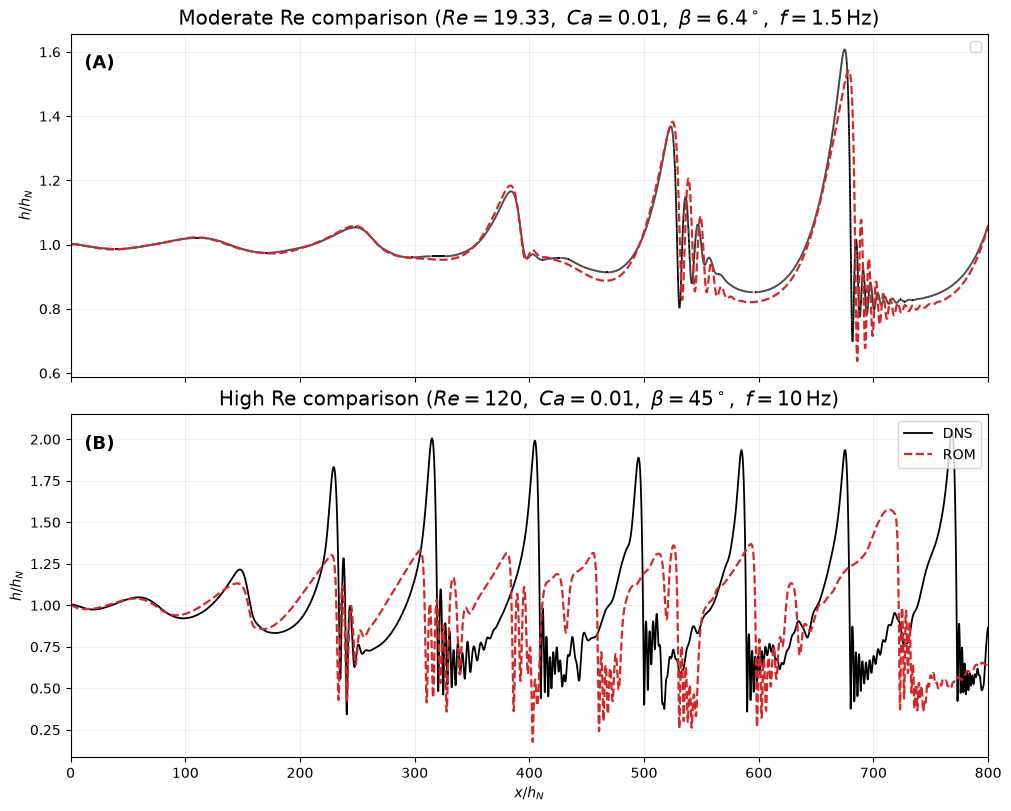

In [1]:
import matplotlib.pyplot as plt
fig_section2, section2_axes = plt.subplots(
    2, 1, figsize=(10, 8), sharex=True, layout="constrained"
)
# Self-contained data loading for the section 2 comparison.
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

COMPARISON_TIME = 460.0
project_root = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml")
dns_case = project_root / "codes/basilisk/physics-tests/bc-blowup-fix/length-check/L800"
rom_case = project_root / "codes/rom-solver/inclined-frequency/cases/Re120_Ca0_010_beta45_f10Hz_L800_N4000"
with h5py.File(rom_case / "thinfilm_training_data.h5", "r") as rom_file:
    rom_x = np.asarray(rom_file["x"][:]).reshape(-1)
    rom_times = np.asarray(rom_file["time"][:]).reshape(-1)
    matches = np.flatnonzero(np.isclose(rom_times, COMPARISON_TIME, rtol=0, atol=1e-8))
    if matches.size != 1:
        raise ValueError("Requested comparison time is not available in ROM output.")
    rom_it = int(matches[0])
    field = rom_file["h"]
    if field.shape == (rom_x.size, rom_times.size):
        rom_height = np.asarray(field[:, rom_it])
    elif field.shape == (rom_times.size, rom_x.size):
        rom_height = np.asarray(field[rom_it, :])
    else:
        raise ValueError(f"Unexpected ROM height shape: {field.shape}")
    rom_parameters = {name: float(np.asarray(rom_file.attrs[name]).item())
                      for name in ["Re", "Ca", "theta_deg", "hN", "TN", "f_dim", "F0"]}
np.testing.assert_allclose([rom_parameters[k] for k in ["Re", "Ca", "theta_deg", "f_dim", "F0"]],
                           [120, 0.01, 45, 10, 0.03])

snapshot_path = dns_case / "output" / f"snapshot_{COMPARISON_TIME:06.0f}.h5"
with h5py.File(snapshot_path, "r") as dns_file:
    np.testing.assert_allclose(float(dns_file["Parameters/time"][()]), COMPARISON_TIME)
    np.testing.assert_allclose(
        [float(dns_file["Parameters/Re"][()]), float(dns_file["Parameters/Ca"][()]),
         np.rad2deg(float(dns_file["Parameters/angle"][()]))], [120, 0.01, 45])
    np.testing.assert_allclose(
        [float(dns_file["Parameters/h0"][()]), float(dns_file["Parameters/t0"][()])],
        [rom_parameters["hN"], rom_parameters["TN"]])
    mesh_points = dns_file["Geometry/Points"][:, :2]
    mesh_topology = dns_file["Topology"][:]
    fraction = np.asarray(dns_file["Cells/f"][:]).reshape(-1)
centers_x = np.zeros(mesh_topology.shape[0])
z_lower = np.full(mesh_topology.shape[0], np.inf)
z_upper = np.full(mesh_topology.shape[0], -np.inf)
for corner in range(mesh_topology.shape[1]):
    vertices = mesh_points[mesh_topology[:, corner]]
    centers_x += vertices[:, 0] / mesh_topology.shape[1]
    z_lower = np.minimum(z_lower, vertices[:, 1])
    z_upper = np.maximum(z_upper, vertices[:, 1])
dns_x, column_indices = np.unique(np.round(centers_x, 12), return_inverse=True)
dns_height = np.bincount(column_indices, weights=fraction * (z_upper - z_lower))
del mesh_points, mesh_topology, fraction, centers_x, z_lower, z_upper, vertices, column_indices
if not all(np.all(np.isfinite(a)) and np.all(a > 0) for a in [dns_height, rom_height]):
    raise ValueError("Invalid film height in comparison.")

with plt.rc_context({"font.family": "serif", "font.size": 12, "pdf.fonttype": 42}):
    fig_comparison = fig_section2
    ax_comparison = section2_axes[1]
    ax_comparison.plot(dns_x, dns_height, color="black", linewidth=1.3,
                       label="DNS")
    ax_comparison.plot(rom_x, rom_height, color="tab:red", linestyle="--", linewidth=1.6,
                       label="ROM")
    ax_comparison.set_xlim(0, 800)
    ax_comparison.set_xlabel(r"$x/h_N$")
    ax_comparison.set_ylabel(r"$h/h_N$")
    ax_comparison.set_title(
        r"High Re comparison ($Re=120,\ Ca=0.01,\ \beta=45^\circ,\ f=10\,\mathrm{Hz}$)")
    ax_comparison.grid(alpha=0.25, linewidth=0.6)
    ax_comparison.legend(frameon=True)
    section2_dir = Path("section2_figures")
    section2_dir.mkdir(parents=True, exist_ok=True)
    figure_stem = section2_dir / f"L800_ROM_interface_t{COMPARISON_TIME:g}"
print(f"Comparison at t={COMPARISON_TIME:g}: DNS {dns_x.size:,} cells, ROM {rom_x.size:,} cells.")
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

liu_dns_dir = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/Setups/basilisk/back2basics/clsvof/LX_2.0_test")
liu_rom_dir = Path("/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-solver/1.5Hz")
LIU_TIME_SECONDS = 10.0
liu_rom = loadmat(liu_rom_dir / f"Freq_1.5Hz_time_{LIU_TIME_SECONDS:.4f}s.mat")
liu_hN = float(liu_rom["hN"].item())
liu_Re = float(liu_rom["Re"].item())
liu_Ca = float(liu_rom["We"].item()) / liu_Re
liu_rom_x = np.asarray(liu_rom["x_dim"]).reshape(-1) / liu_hN
liu_rom_height = np.asarray(liu_rom["hi"]).reshape(-1)  # Already nondimensional.
np.testing.assert_allclose(liu_Re, 19.33, atol=0.005, rtol=0)
if liu_hN <= 0 or liu_rom_x.shape != liu_rom_height.shape:
    raise ValueError("Invalid ROM scale or profile dimensions.")
# Each pair of rows defines one reconstructed DNS interface segment.
liu_vertices = np.loadtxt(liu_dns_dir / f"infc{LIU_TIME_SECONDS:.4f}.dat")
if liu_vertices.ndim != 2 or liu_vertices.shape[1] != 2 or len(liu_vertices) % 2:
    raise ValueError("Unexpected DNS interface segment format.")
liu_segments = (liu_vertices / liu_hN).reshape(-1, 2, 2)
if not all(np.all(np.isfinite(a)) for a in [liu_segments, liu_rom_x, liu_rom_height]):
    raise ValueError("Nonfinite profile values.")
# Select visible segments without joining separate reconstructed facets.
liu_visible = (liu_segments[:, :, 0].max(axis=1) >= 0) & (liu_segments[:, :, 0].min(axis=1) <= 800)
liu_rom_visible = (liu_rom_x >= 0) & (liu_rom_x <= 800)
with plt.rc_context({"font.family": "serif", "font.size": 12, "pdf.fonttype": 42}):
    fig_liu = fig_section2
    ax_liu = section2_axes[0]
    ax_liu.add_collection(LineCollection(liu_segments[liu_visible], colors="black", linewidths=1.3))
    ax_liu.plot(liu_rom_x[liu_rom_visible], liu_rom_height[liu_rom_visible],
                color="tab:red", linestyle="--", linewidth=1.6)
    ax_liu.autoscale_view()
    ax_liu.set_xlim(0, 800)
    ax_liu.set_xlabel(r"$x/h_N$")
    ax_liu.set_ylabel(r"$h/h_N$")
    ax_liu.set_title(r"Moderate Re comparison ($Re=19.33,\ Ca=0.01,\ \beta=6.4^\circ,\ f=1.5\,\mathrm{Hz}$)")
    ax_liu.legend(handles=[Line2D([0], [0], color="black", linewidth=1.3, label="DNS"),
                           Line2D([0], [0], color="tab:red", linestyle="--", linewidth=1.6, label="ROM")])
    ax_liu.grid(alpha=0.25, linewidth=0.6)
    liu_output = Path("section2_figures")
    liu_output.mkdir(parents=True, exist_ok=True)
print(f"Nominal time: {LIU_TIME_SECONDS:g} s; common h_N: {liu_hN:.10g} m")
print(f"Saved ROM parameters: Re={liu_Re:.8g}, Ca={liu_Ca:.8g}")
section2_axes[0].set_xlabel("")
for panel_ax, label in zip(section2_axes, ["(A)", "(B)"]):
    panel_ax.text(0.015, 0.94, label, transform=panel_ax.transAxes,
                  va="top", ha="left", fontsize=13, fontweight="bold")
    panel_ax.legend(loc="upper right", frameon=True)
section2_output = Path("section2_figures")
section2_output.mkdir(parents=True, exist_ok=True)
fig_section2.savefig(section2_output / "DNS_ROM_comparisons.pdf", format="pdf")
fig_section2.savefig(section2_output / "DNS_ROM_comparisons.png", dpi=300)
plt.show()


## Section 3: height and closure corrections in two spatial windows

Re = 120, Ca = 0.01, β = 45°, t = 1800. Top row: height. Bottom row: four closure corrections. Left column: linear regime, x/h_N = 0–200. Right column: non-linear regime, x/h_N = 400–600. Both panels in each row share y-limits. Profiles come from the source recorded in statistics configuration `3ff02fc6138a`.

Display processing: only `delta_Px_ML` is smoothed using a 51-point, third-order Savitzky–Golay filter. No portion of the curve is set to zero. Original profiles remain unchanged; no mean subtraction or standard-deviation scaling is applied.

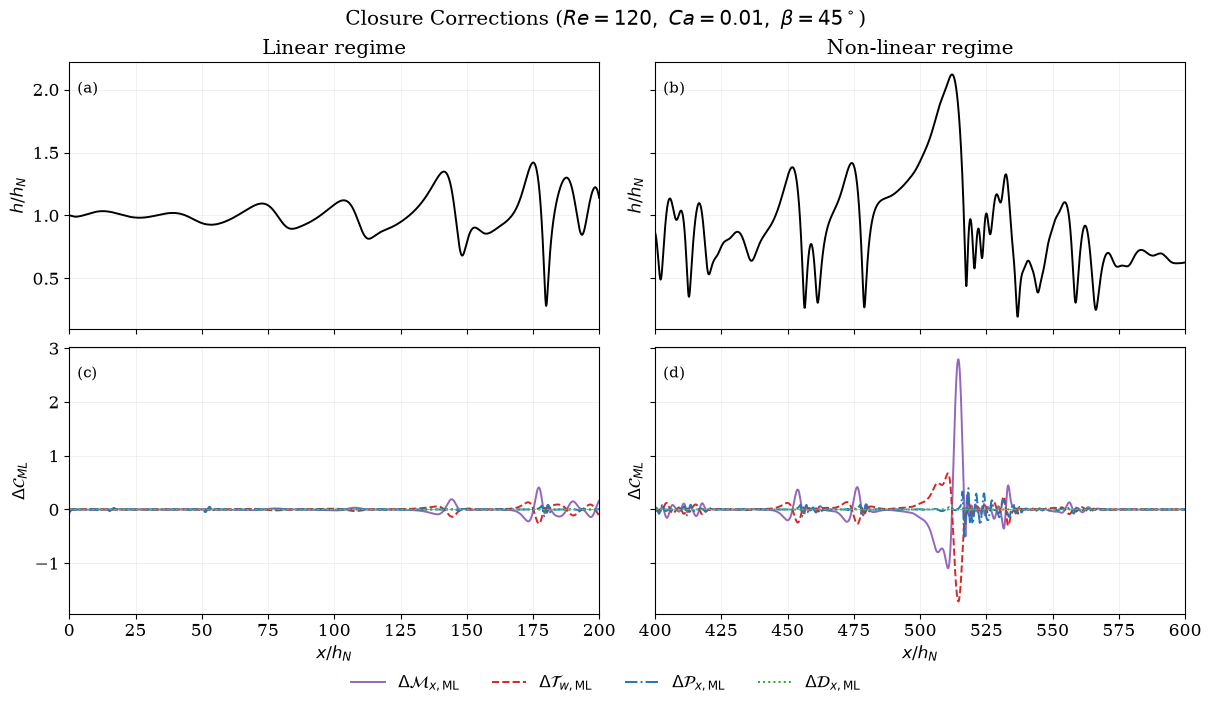

Source: /blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/datasets/BasC/param_space/ClosureData/thinfilm_closure_data_Re120_Ca0_010_theta45.h5
Selected t=1800; windows: [(0, 200), (400, 600)]


In [1]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

statistics_file = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/data-preprocessing/conditional_statistics/results/3ff02fc6138a/"
    "thinfilm_closure_data_Re120_Ca0_010_theta45_statistics.h5"
)
PROFILE_TIME = 1800.0
PROFILE_X_LIMITS = (0, 750)
profile_fields = ["h", "delta_Mx_ML", "delta_Tw_ML", "delta_Px_ML", "delta_Dx_ML"]
profile_labels = [
    r"$h/h_N$",
    r"$\Delta\mathcal{M}_{x,\mathrm{ML}}$",
    r"$\Delta\mathcal{T}_{w,\mathrm{ML}}$",
    r"$\Delta\mathcal{P}_{x,\mathrm{ML}}$",
    r"$\Delta\mathcal{D}_{x,\mathrm{ML}}$",
]
with h5py.File(statistics_file, "r") as stats_file:
    recorded_source = stats_file.attrs["source_path"]
    if isinstance(recorded_source, bytes):
        recorded_source = recorded_source.decode()
    source_file = Path(recorded_source)
with h5py.File(source_file, "r") as closure_file:
    profile_x = np.asarray(closure_file["x"][:]).reshape(-1)
    profile_times = np.asarray(closure_file["t"][:]).reshape(-1)
    time_indices = np.flatnonzero(np.isclose(profile_times, PROFILE_TIME, rtol=0, atol=1e-8))
    if len(time_indices) != 1:
        raise ValueError("Expected exactly one snapshot at t=1800.")
    time_index = int(time_indices[0])
    profile_parameters = {name: float(closure_file["parameters"][name][()])
                          for name in ["Re", "Ca", "angle"]}
    np.testing.assert_allclose(
        [profile_parameters["Re"], profile_parameters["Ca"], np.rad2deg(profile_parameters["angle"])],
        [120, 0.01, 45],
    )
    spatial_profiles = {}
    for name in profile_fields:
        dataset = closure_file[name]
        if dataset.shape == (len(profile_x), len(profile_times)):
            values = np.asarray(dataset[:, time_index])
        elif dataset.shape == (len(profile_times), len(profile_x)):
            values = np.asarray(dataset[time_index, :])
        else:
            raise ValueError(f"Unexpected {name} shape: {dataset.shape}")
        if not np.all(np.isfinite(values)):
            raise ValueError(f"Nonfinite values in {name}")
        spatial_profiles[name] = values

from scipy.signal import savgol_filter

# Display-only processing requested for the pressure correction.
# Retain spatial_profiles unchanged for analysis.
PX_SAVGOL_WINDOW = 51
PX_SAVGOL_ORDER = 3
plot_profiles = {name: values.copy() for name, values in spatial_profiles.items()}
px_smoothed = savgol_filter(spatial_profiles["delta_Px_ML"],
                            window_length=PX_SAVGOL_WINDOW,
                            polyorder=PX_SAVGOL_ORDER, mode="interp")
plot_profiles["delta_Px_ML"] = px_smoothed

closure_names = profile_fields[1:]
closure_labels = profile_labels[1:]
window_ranges = [(0, 200), (400, 600)]
line_styles = [
    ("tab:purple", "-"), ("tab:red", "--"),
    ("tab:blue", "-."), ("tab:green", ":"),
]
with plt.rc_context({"font.family": "serif", "font.size": 12, "pdf.fonttype": 42}):
    fig_profiles, axes_profiles = plt.subplots(
        2, 2, figsize=(12, 7), sharex="col", sharey="row", layout="constrained"
    )
    for column, window in enumerate(window_ranges):
        visible = (profile_x >= window[0]) & (profile_x <= window[1])
        ax_height = axes_profiles[0, column]
        ax_corrections = axes_profiles[1, column]
        ax_height.plot(profile_x[visible], spatial_profiles["h"][visible],
                       color="black", linewidth=1.4)
        ax_height.set_ylabel(r"$h/h_N$")
        ax_height.set_title(["Linear regime", "Non-linear regime"][column])
        for name, label, (color, linestyle) in zip(closure_names, closure_labels, line_styles):
            ax_corrections.plot(profile_x[visible], plot_profiles[name][visible],
                                color=color, linestyle=linestyle, linewidth=1.4, label=label)
        ax_corrections.axhline(0, color="0.6", linestyle="--", linewidth=0.6)
        ax_corrections.set_xlabel(r"$x/h_N$")
        ax_corrections.set_ylabel(r"$\Delta \mathcal{C}_{ML}$")
        for row, ax in enumerate([ax_height, ax_corrections]):
            ax.set_xlim(*window)
            ax.grid(alpha=0.2, linewidth=0.6)
            ax.text(0.015, 0.93, f"({chr(97 + row * 2 + column)})",
                    transform=ax.transAxes, va="top", fontsize=11)
    handles, labels = axes_profiles[1, 0].get_legend_handles_labels()
    fig_profiles.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
    fig_profiles.suptitle(r"Closure Corrections ($Re=120,\ Ca=0.01,\ \beta=45^\circ$)")
    section3_dir = Path("section3_figures")
    section3_dir.mkdir(parents=True, exist_ok=True)
    profile_stem = section3_dir / "closure_profiles_Re120_Ca0_010_beta45_t1800"
    fig_profiles.savefig(profile_stem.with_suffix(".pdf"), format="pdf")
    fig_profiles.savefig(profile_stem.with_suffix(".png"), dpi=300)
    plt.show()
print(f"Source: {source_file}")
print(f"Selected t={profile_times[time_index]:g}; windows: {window_ranges}")


## Section 3: representative raw closure PDFs

Four representative cases span Re = 10–200, Ca = 0.005–0.1, and β = 6.4°, 45°, 90°. A single row shows the four closure quantities, with all cases overlaid in every panel. Distributions use the `All/pdf/raw` results in configuration `3ff02fc6138a`: no mean subtraction or standard-deviation scaling. Densities are plotted as stored, without smoothing; the axes are linear.

Each curve is displayed only within its own raw mean ± 2 standard deviations, using the stored full-distribution moments. Truncated curves are not renormalized; the horizontal axes retain raw closure values.

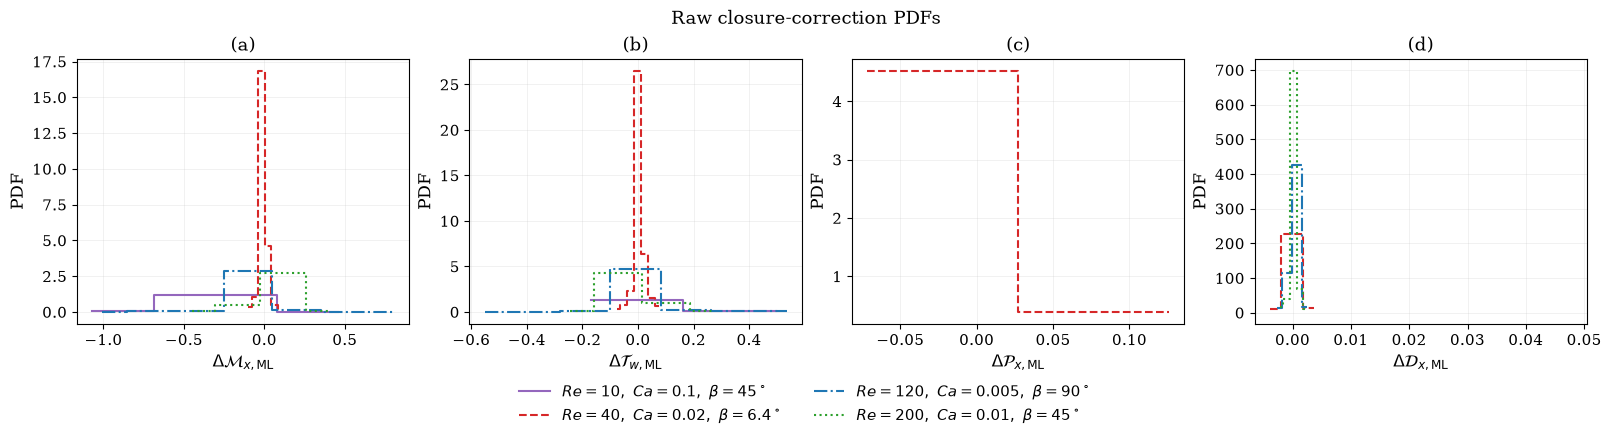

In [1]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

pdf_results_dir = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/data-preprocessing/conditional_statistics/results/3ff02fc6138a"
)
representative_cases = [(10, 0.1, 45), (40, 0.02, 6.4),
                        (120, 0.005, 90), (200, 0.01, 45)]
pdf_quantities = ["delta_Mx_ML", "delta_Tw_ML", "delta_Px_ML", "delta_Dx_ML"]
pdf_axis_labels = [r"$\Delta\mathcal{M}_{x,\mathrm{ML}}$",
                   r"$\Delta\mathcal{T}_{w,\mathrm{ML}}$",
                   r"$\Delta\mathcal{P}_{x,\mathrm{ML}}$",
                   r"$\Delta\mathcal{D}_{x,\mathrm{ML}}$"]
pdf_styles = [("tab:purple", "-"), ("tab:red", "--"),
              ("tab:blue", "-."), ("tab:green", ":")]
with plt.rc_context({"font.family": "serif", "font.size": 11,
                     "pdf.fonttype": 42, "axes.labelsize": 12}):
    fig_pdfs, axes_pdfs = plt.subplots(1, 4, figsize=(16, 4.3), layout="constrained")
    for (case_re, case_ca, case_beta), (color, linestyle) in zip(representative_cases, pdf_styles):
        case_ca_tag = f"{case_ca:.3f}".replace(".", "_")
        case_beta_tag = f"{case_beta:g}".replace(".", "_")
        result_path = pdf_results_dir / (
            f"thinfilm_closure_data_Re{case_re:03d}_Ca{case_ca_tag}_"
            f"theta{case_beta_tag}_statistics.h5"
        )
        case_label = rf"$Re={case_re},\ Ca={case_ca:g},\ \beta={case_beta:g}^\circ$"
        with h5py.File(result_path, "r") as result:
            for ax, quantity in zip(axes_pdfs, pdf_quantities):
                group = result[f"qois/{quantity}/All/pdf/raw"]
                edges = np.asarray(group["bin_edges"][:])
                density = np.asarray(group["density"][:])
                if (edges.size != density.size + 1 or np.any(np.diff(edges) <= 0)
                        or not np.all(np.isfinite(density)) or np.any(density < 0)):
                    raise ValueError(f"Invalid PDF: {result_path.name}, {quantity}")
                integral = float(np.sum(density * np.diff(edges)))
                np.testing.assert_allclose(integral, 1, rtol=1e-6, atol=1e-8)
                # Retain zero-density bins on linear axes.
                display_density = density
                centers = 0.5 * (edges[:-1] + edges[1:])
                pdf_moments = result[f"qois/{quantity}/All/pdf"].attrs
                mean_value = float(pdf_moments["mean"])
                std_value = float(pdf_moments["std"])
                lower, upper = mean_value - 2 * std_value, mean_value + 2 * std_value
                within_two_std = (centers >= lower) & (centers <= upper)
                ax.plot(centers[within_two_std], display_density[within_two_std],
                        drawstyle="steps-mid", color=color, linestyle=linestyle,
                        linewidth=1.5, label=case_label)
    for index, (ax, label) in enumerate(zip(axes_pdfs, pdf_axis_labels)):
        ax.set_yscale("linear")
        ax.set_xlabel(label)
        ax.set_ylabel("PDF")
        ax.set_title(f"({chr(97 + index)})")
        ax.grid(alpha=0.2, linewidth=0.6)
        ax.tick_params(direction="out")
    handles, labels = axes_pdfs[0].get_legend_handles_labels()
    fig_pdfs.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
    fig_pdfs.suptitle("Raw closure-correction PDFs")
    pdf_output_dir = Path("section3_figures")
    pdf_output_dir.mkdir(parents=True, exist_ok=True)
    fig_pdfs.savefig(pdf_output_dir / "representative_closure_PDFs.pdf", format="pdf")
    fig_pdfs.savefig(pdf_output_dir / "representative_closure_PDFs.png", dpi=300)
    plt.show()


## Section 3: neighboring-field Pearson correlations

Same four representative cases and `All` region from configuration `3ff02fc6138a`. Each column is one closure quantity. Top row: correlation with neighboring $h$; bottom row: correlation with neighboring $q$. The signed offset is $ell=x_{mathrm{neighbor}}-x_{mathrm{closure}}$. Stored signed Pearson coefficients are plotted directly, with no absolute values or smoothing. The ±2 standard-deviation display restriction used for PDFs does not apply to these correlations.

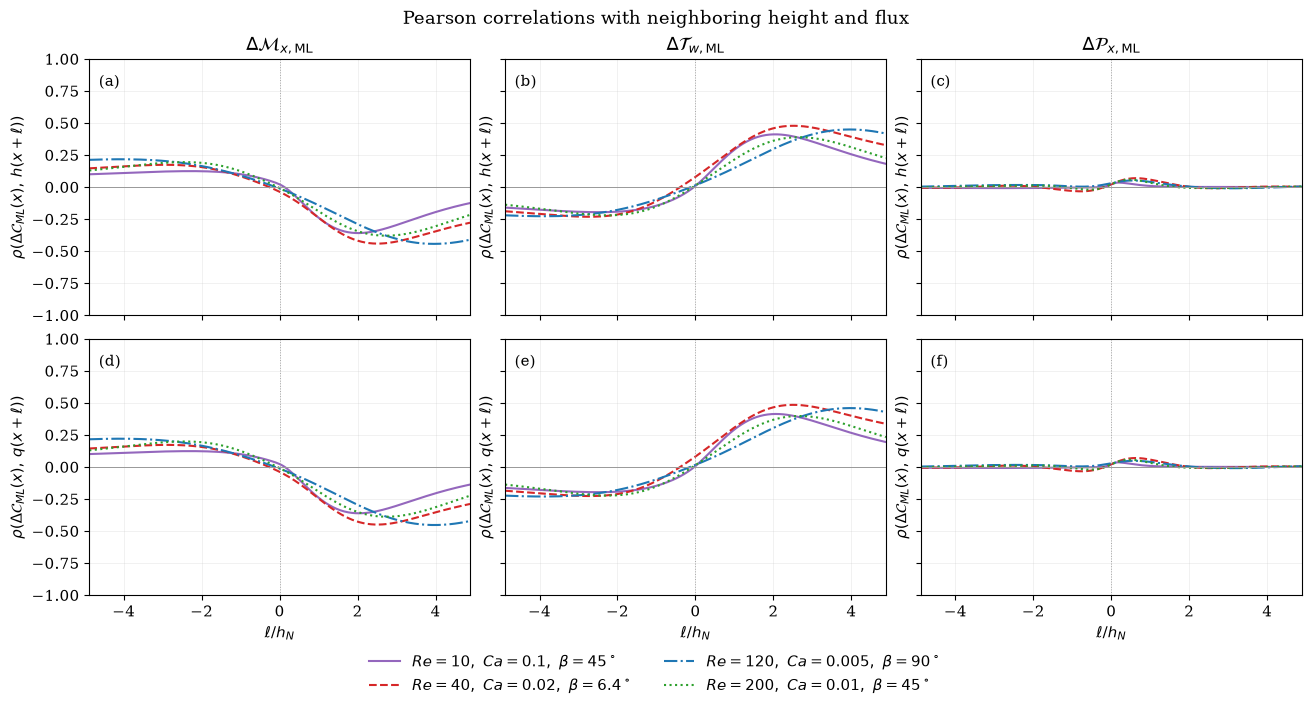

In [1]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

pearson_results_dir = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/data-preprocessing/conditional_statistics/results/3ff02fc6138a"
)
pearson_cases = [(10, 0.1, 45), (40, 0.02, 6.4),
                 (120, 0.005, 90), (200, 0.01, 45)]
pearson_quantities = ["delta_Mx_ML", "delta_Tw_ML", "delta_Px_ML"]
pearson_labels = [r"\Delta\mathcal{M}_{x,\mathrm{ML}}",
                  r"\Delta\mathcal{T}_{w,\mathrm{ML}}",
                  r"\Delta\mathcal{P}_{x,\mathrm{ML}}"]
pearson_styles = [("tab:purple", "-"), ("tab:red", "--"),
                  ("tab:blue", "-."), ("tab:green", ":")]
with plt.rc_context({"font.family": "serif", "font.size": 11, "pdf.fonttype": 42}):
    fig_pearson, axes_pearson = plt.subplots(
        2, 3, figsize=(13, 7), sharex=True, sharey=True, layout="constrained"
    )
    for (case_re, case_ca, case_beta), (color, linestyle) in zip(pearson_cases, pearson_styles):
        ca_tag_case = f"{case_ca:.3f}".replace(".", "_")
        beta_tag_case = f"{case_beta:g}".replace(".", "_")
        result_path = pearson_results_dir / (
            f"thinfilm_closure_data_Re{case_re:03d}_Ca{ca_tag_case}_"
            f"theta{beta_tag_case}_statistics.h5"
        )
        label = rf"$Re={case_re},\ Ca={case_ca:g},\ \beta={case_beta:g}^\circ$"
        with h5py.File(result_path, "r") as result:
            distances = np.asarray(result["distances"][:]).reshape(-1)
            for column, quantity in enumerate(pearson_quantities):
                for row, neighbor in enumerate(["h", "q"]):
                    coefficients = np.asarray(result[f"qois/{quantity}/All/pearson/{neighbor}"][:]).reshape(-1)
                    if coefficients.shape != distances.shape:
                        raise ValueError("Pearson coordinate/array shape mismatch.")
                    finite = np.isfinite(coefficients)
                    if np.any(np.abs(coefficients[finite]) > 1 + 1e-8):
                        raise ValueError("Pearson coefficient outside [-1,1].")
                    axes_pearson[row, column].plot(
                        distances, coefficients, color=color, linestyle=linestyle,
                        linewidth=1.5, label=label,
                    )
    for column, closure_label in enumerate(pearson_labels):
        axes_pearson[0, column].set_title(rf"${closure_label}$")
        axes_pearson[1, column].set_xlabel(r"$\ell/h_N$")
        for row, neighbor in enumerate(["h", "q"]):
            ax = axes_pearson[row, column]
            ax.axhline(0, color="0.6", linewidth=0.7)
            ax.axvline(0, color="0.65", linewidth=0.7, linestyle=":")
            ax.set_ylim(-1, 1)
            ax.set_xlim(distances.min(), distances.max())
            ax.set_ylabel(rf"$\rho(\Delta\mathcal{{C}}_{{ML}}(x),\,{neighbor}(x+\ell))$")
            ax.grid(alpha=0.2, linewidth=0.6)
            ax.text(0.025, 0.94, f"({chr(97 + row * 3 + column)})",
                    transform=ax.transAxes, va="top", fontsize=11)
    handles, labels = axes_pearson[0, 0].get_legend_handles_labels()
    fig_pearson.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
    fig_pearson.suptitle("Pearson correlations with neighboring height and flux")
    pearson_output_dir = Path("section3_figures")
    pearson_output_dir.mkdir(parents=True, exist_ok=True)
    fig_pearson.savefig(pearson_output_dir / "representative_closure_Pearson_h_q.pdf", format="pdf")
    fig_pearson.savefig(pearson_output_dir / "representative_closure_Pearson_h_q.png", dpi=300)
    plt.show()


## Correction-model validation NRMSE versus half-neighbor width

One curve per closure quantity, with one result at each distinct physical half-neighbor width. When multiple runs share a width, the run with the smallest sampling interval is selected consistently for all quantities. Widths use DNS spacing 0.0488 in units of h_N. The source is the top-level correction runs in `sweep_01`, excluding archived `v01` runs. Vertical axes are logarithmic.

Metrics are saved pooled validation NRMSE. The zero-width evaluation uses 8,599,161 samples versus 8,106,933 for the other runs, so differences cannot be attributed solely to neighborhood width.

The dashed horizontal line marks the lowest saved NRMSE among the selected runs for that closure quantity.

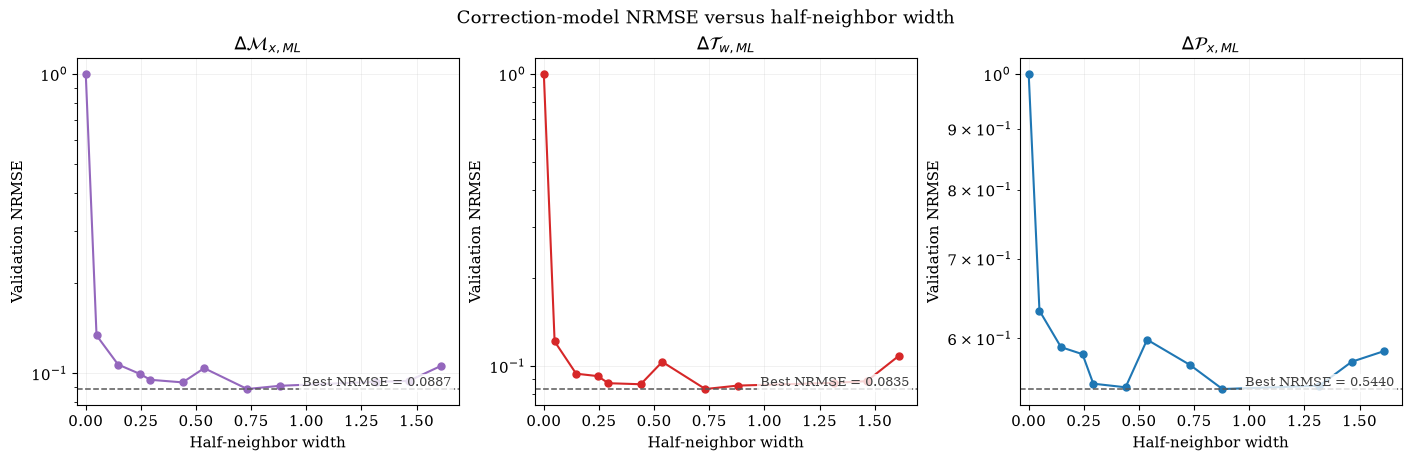

Unique half-neighbor widths per quantity: 12


In [1]:
from pathlib import Path
import csv
import json
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

sweep_root = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/ml-models/thinfilm_mlp/runs/sweep_01"
)
DX_DNS = 0.0488
rmse_targets = ["delta_Mx_ML", "delta_Tw_ML", "delta_Px_ML"]
rmse_labels = [r"$\Delta\mathcal{M}_{x,ML}$", r"$\Delta\mathcal{T}_{w,ML}$",
               r"$\Delta\mathcal{P}_{x,ML}$"]
width_records = []
for run_dir in sorted(sweep_root.glob("corrections_j*_s*")):
    match = re.fullmatch(r"corrections_j(\d+)_s(\d+)", run_dir.name)
    metrics_path = run_dir / "eval_val" / "metrics.csv"
    if match is None or not metrics_path.is_file():
        continue
    j, stride = map(int, match.groups())
    config = json.loads((run_dir / "run_config.json").read_text())
    assert config["args"]["half_window"] == j and config["args"]["stride"] == stride
    with metrics_path.open(newline="") as stream:
        pooled = [row for row in csv.DictReader(stream)
                  if row["case"] == "POOLED" and row["target"] in rmse_targets]
    if len(pooled) != len(rmse_targets):
        raise ValueError(f"Missing/duplicate pooled targets: {run_dir.name}")
    for row in pooled:
        rmse = float(row["RMSE"])
        if not np.isfinite(rmse) or rmse <= 0:
            raise ValueError(f"Invalid RMSE: {run_dir.name}")
        width_records.append(dict(run=run_dir.name, j=j, s=stride,
                                  half_width=j * stride * DX_DNS,
                                  target=row["target"], RMSE=rmse, NRMSE=float(row["NRMSE"]), n=int(row["n"])))
# At repeated physical widths, consistently select the densest sampling.
selected_by_width = {}
for record in width_records:
    key = (record["target"], round(record["half_width"], 10))
    if key not in selected_by_width or record["s"] < selected_by_width[key]["s"]:
        selected_by_width[key] = record
selected_records = list(selected_by_width.values())
with plt.rc_context({"font.family": "serif", "font.size": 11, "pdf.fonttype": 42}):
    fig_width, axes_width = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
    for ax, target, title, color in zip(axes_width, rmse_targets, rmse_labels,
                                       ["tab:purple", "tab:red", "tab:blue"]):
        records = sorted([r for r in selected_records if r["target"] == target],
                         key=lambda r: r["half_width"])
        ax.plot([r["half_width"] for r in records], [r["NRMSE"] for r in records],
                color=color, marker="o", markersize=5, linewidth=1.5)
        ax.set_title(title)
        ax.set_xlabel("Half-neighbor width")
        ax.set_ylabel("Validation NRMSE")
        best_nrmse = min(r["NRMSE"] for r in records)
        ax.axhline(best_nrmse, color="0.35", linestyle="--", linewidth=1.1)
        ax.text(0.98, best_nrmse, f"Best NRMSE = {best_nrmse:.4f}",
                transform=ax.get_yaxis_transform(), ha="right", va="bottom",
                fontsize=9, color="0.25",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=2))
        ax.set_yscale("log")
        ax.set_xlim(left=-0.04)
        ax.grid(alpha=0.2, linewidth=0.6)
    fig_width.suptitle("Correction-model NRMSE versus half-neighbor width")
    width_output = Path("section3_figures")
    width_output.mkdir(parents=True, exist_ok=True)
    fig_width.savefig(width_output / "corrections_NRMSE_vs_half_neighbor_width.pdf", format="pdf")
    fig_width.savefig(width_output / "corrections_NRMSE_vs_half_neighbor_width.png", dpi=300)
    with (width_output / "corrections_NRMSE_vs_half_neighbor_width.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(selected_records[0]))
        writer.writeheader()
        writer.writerows(sorted(selected_records, key=lambda r: (r["target"], r["half_width"])))
    plt.show()
print(f"Unique half-neighbor widths per quantity: {len(selected_records) // len(rmse_targets)}")


## Aligned neighboring correlations and model error

Columns: momentum-flux derivative, wall-shear, and pressure corrections. Top and middle rows: Pearson correlation with neighboring height and flux for the four representative cases. Bottom row: pooled validation NRMSE versus half-neighbor width, with its minimum labeled. Pearson curves and pooled model errors summarize different populations; alignment is for visual comparison, not a case-by-case error relationship.

Unique half-neighbor widths per quantity: 12


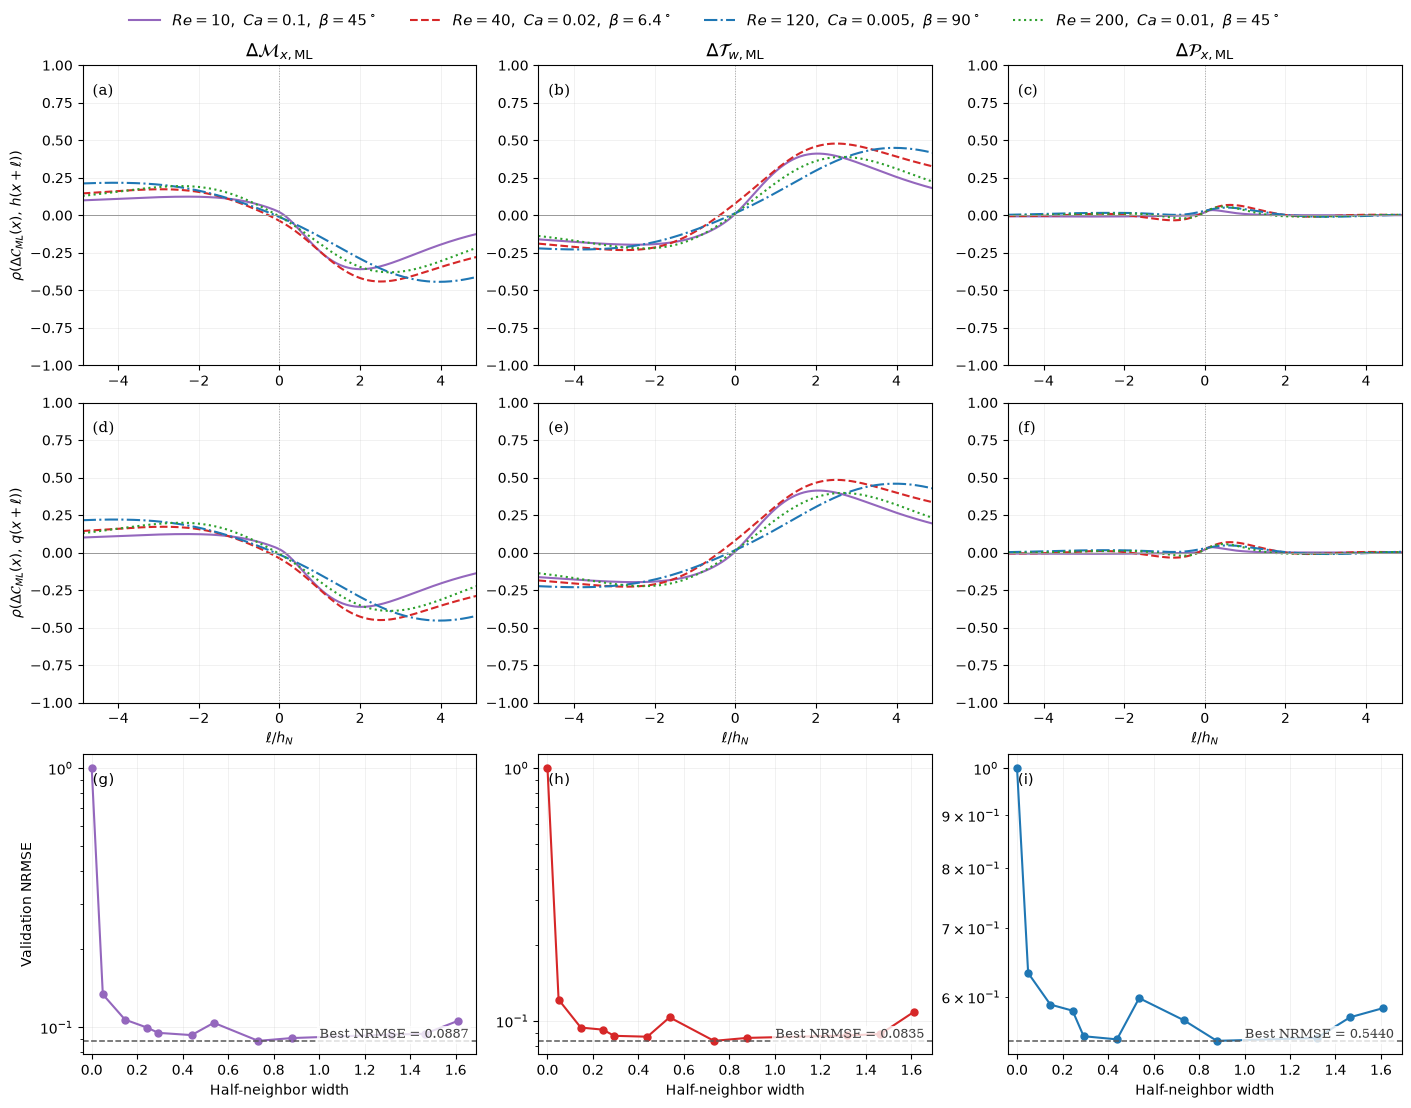

In [1]:
import matplotlib.pyplot as plt
fig_aligned, aligned_axes = plt.subplots(3, 3, figsize=(14, 11), layout="constrained")
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

pearson_results_dir = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/data-preprocessing/conditional_statistics/results/3ff02fc6138a"
)
pearson_cases = [(10, 0.1, 45), (40, 0.02, 6.4),
                 (120, 0.005, 90), (200, 0.01, 45)]
pearson_quantities = ["delta_Mx_ML", "delta_Tw_ML", "delta_Px_ML"]
pearson_labels = [r"\Delta\mathcal{M}_{x,\mathrm{ML}}",
                  r"\Delta\mathcal{T}_{w,\mathrm{ML}}",
                  r"\Delta\mathcal{P}_{x,\mathrm{ML}}"]
pearson_styles = [("tab:purple", "-"), ("tab:red", "--"),
                  ("tab:blue", "-."), ("tab:green", ":")]
with plt.rc_context({"font.family": "serif", "font.size": 11, "pdf.fonttype": 42}):
    fig_pearson = fig_aligned
    axes_pearson = aligned_axes[:2, :]
    for (case_re, case_ca, case_beta), (color, linestyle) in zip(pearson_cases, pearson_styles):
        ca_tag_case = f"{case_ca:.3f}".replace(".", "_")
        beta_tag_case = f"{case_beta:g}".replace(".", "_")
        result_path = pearson_results_dir / (
            f"thinfilm_closure_data_Re{case_re:03d}_Ca{ca_tag_case}_"
            f"theta{beta_tag_case}_statistics.h5"
        )
        label = rf"$Re={case_re},\ Ca={case_ca:g},\ \beta={case_beta:g}^\circ$"
        with h5py.File(result_path, "r") as result:
            distances = np.asarray(result["distances"][:]).reshape(-1)
            for column, quantity in enumerate(pearson_quantities):
                for row, neighbor in enumerate(["h", "q"]):
                    coefficients = np.asarray(result[f"qois/{quantity}/All/pearson/{neighbor}"][:]).reshape(-1)
                    if coefficients.shape != distances.shape:
                        raise ValueError("Pearson coordinate/array shape mismatch.")
                    finite = np.isfinite(coefficients)
                    if np.any(np.abs(coefficients[finite]) > 1 + 1e-8):
                        raise ValueError("Pearson coefficient outside [-1,1].")
                    axes_pearson[row, column].plot(
                        distances, coefficients, color=color, linestyle=linestyle,
                        linewidth=1.5, label=label,
                    )
    for column, closure_label in enumerate(pearson_labels):
        axes_pearson[0, column].set_title(rf"${closure_label}$")
        axes_pearson[1, column].set_xlabel(r"$\ell/h_N$")
        for row, neighbor in enumerate(["h", "q"]):
            ax = axes_pearson[row, column]
            ax.axhline(0, color="0.6", linewidth=0.7)
            ax.axvline(0, color="0.65", linewidth=0.7, linestyle=":")
            ax.set_ylim(-1, 1)
            ax.set_xlim(distances.min(), distances.max())
            ax.set_ylabel(rf"$\rho(\Delta\mathcal{{C}}_{{ML}}(x),\,{neighbor}(x+\ell))$")
            ax.grid(alpha=0.2, linewidth=0.6)
            ax.text(0.025, 0.94, f"({chr(97 + row * 3 + column)})",
                    transform=ax.transAxes, va="top", fontsize=11)
    handles, labels = axes_pearson[0, 0].get_legend_handles_labels()
    fig_pearson.legend(handles, labels, loc="outside upper center", ncol=4, frameon=False)
    pearson_output_dir = Path("section3_figures")
    pearson_output_dir.mkdir(parents=True, exist_ok=True)
from pathlib import Path
import csv
import json
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

sweep_root = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/ml-models/thinfilm_mlp/runs/sweep_01"
)
DX_DNS = 0.0488
rmse_targets = ["delta_Mx_ML", "delta_Tw_ML", "delta_Px_ML"]
rmse_labels = [r"$\Delta\mathcal{M}_{x,ML}$", r"$\Delta\mathcal{T}_{w,ML}$",
               r"$\Delta\mathcal{P}_{x,ML}$"]
width_records = []
for run_dir in sorted(sweep_root.glob("corrections_j*_s*")):
    match = re.fullmatch(r"corrections_j(\d+)_s(\d+)", run_dir.name)
    metrics_path = run_dir / "eval_val" / "metrics.csv"
    if match is None or not metrics_path.is_file():
        continue
    j, stride = map(int, match.groups())
    config = json.loads((run_dir / "run_config.json").read_text())
    assert config["args"]["half_window"] == j and config["args"]["stride"] == stride
    with metrics_path.open(newline="") as stream:
        pooled = [row for row in csv.DictReader(stream)
                  if row["case"] == "POOLED" and row["target"] in rmse_targets]
    if len(pooled) != len(rmse_targets):
        raise ValueError(f"Missing/duplicate pooled targets: {run_dir.name}")
    for row in pooled:
        rmse = float(row["RMSE"])
        if not np.isfinite(rmse) or rmse <= 0:
            raise ValueError(f"Invalid RMSE: {run_dir.name}")
        width_records.append(dict(run=run_dir.name, j=j, s=stride,
                                  half_width=j * stride * DX_DNS,
                                  target=row["target"], RMSE=rmse, NRMSE=float(row["NRMSE"]), n=int(row["n"])))
# At repeated physical widths, consistently select the densest sampling.
selected_by_width = {}
for record in width_records:
    key = (record["target"], round(record["half_width"], 10))
    if key not in selected_by_width or record["s"] < selected_by_width[key]["s"]:
        selected_by_width[key] = record
selected_records = list(selected_by_width.values())
with plt.rc_context({"font.family": "serif", "font.size": 11, "pdf.fonttype": 42}):
    fig_width = fig_aligned
    axes_width = aligned_axes[2, :]
    for ax, target, title, color in zip(axes_width, rmse_targets, rmse_labels,
                                       ["tab:purple", "tab:red", "tab:blue"]):
        records = sorted([r for r in selected_records if r["target"] == target],
                         key=lambda r: r["half_width"])
        ax.plot([r["half_width"] for r in records], [r["NRMSE"] for r in records],
                color=color, marker="o", markersize=5, linewidth=1.5)
        ax.set_title(title)
        ax.set_xlabel("Half-neighbor width")
        ax.set_ylabel("Validation NRMSE")
        best_nrmse = min(r["NRMSE"] for r in records)
        ax.axhline(best_nrmse, color="0.35", linestyle="--", linewidth=1.1)
        ax.text(0.98, best_nrmse, f"Best NRMSE = {best_nrmse:.4f}",
                transform=ax.get_yaxis_transform(), ha="right", va="bottom",
                fontsize=9, color="0.25",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=2))
        ax.set_yscale("log")
        ax.set_xlim(left=-0.04)
        ax.grid(alpha=0.2, linewidth=0.6)
    width_output = Path("section3_figures")
    width_output.mkdir(parents=True, exist_ok=True)
    with (width_output / "corrections_NRMSE_vs_half_neighbor_width.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(selected_records[0]))
        writer.writeheader()
        writer.writerows(sorted(selected_records, key=lambda r: (r["target"], r["half_width"])))
print(f"Unique half-neighbor widths per quantity: {len(selected_records) // len(rmse_targets)}")
for row in range(3):
    for column in range(3):
        panel_ax = aligned_axes[row, column]
        if row == 2:
            panel_ax.set_title("")
            panel_ax.text(0.025, 0.94, f"({chr(97 + row * 3 + column)})",
                          transform=panel_ax.transAxes, va="top", fontsize=11)
        if column > 0:
            panel_ax.set_ylabel("")
aligned_output = Path("section3_figures")
aligned_output.mkdir(parents=True, exist_ok=True)
fig_aligned.savefig(aligned_output / "Pearson_and_NRMSE_neighbor_width.pdf", format="pdf")
fig_aligned.savefig(aligned_output / "Pearson_and_NRMSE_neighbor_width.png", dpi=300)
plt.show()


## Functional MLP: spatial correction predictions at t = 1800

Four simulations, with wall-shear correction on the left and momentum-flux derivative correction on the right. Each compares the six input-feature variants in `ablation_01/layers1_width16` against the DNS closure correction. Predictions use each target's `best.pt`, recorded input ordering, and saved input/output normalization. Profiles cover x/h_N = 400–600 without filtering or phase alignment. These are full spatial snapshots, not metrics restricted to a held-out split.

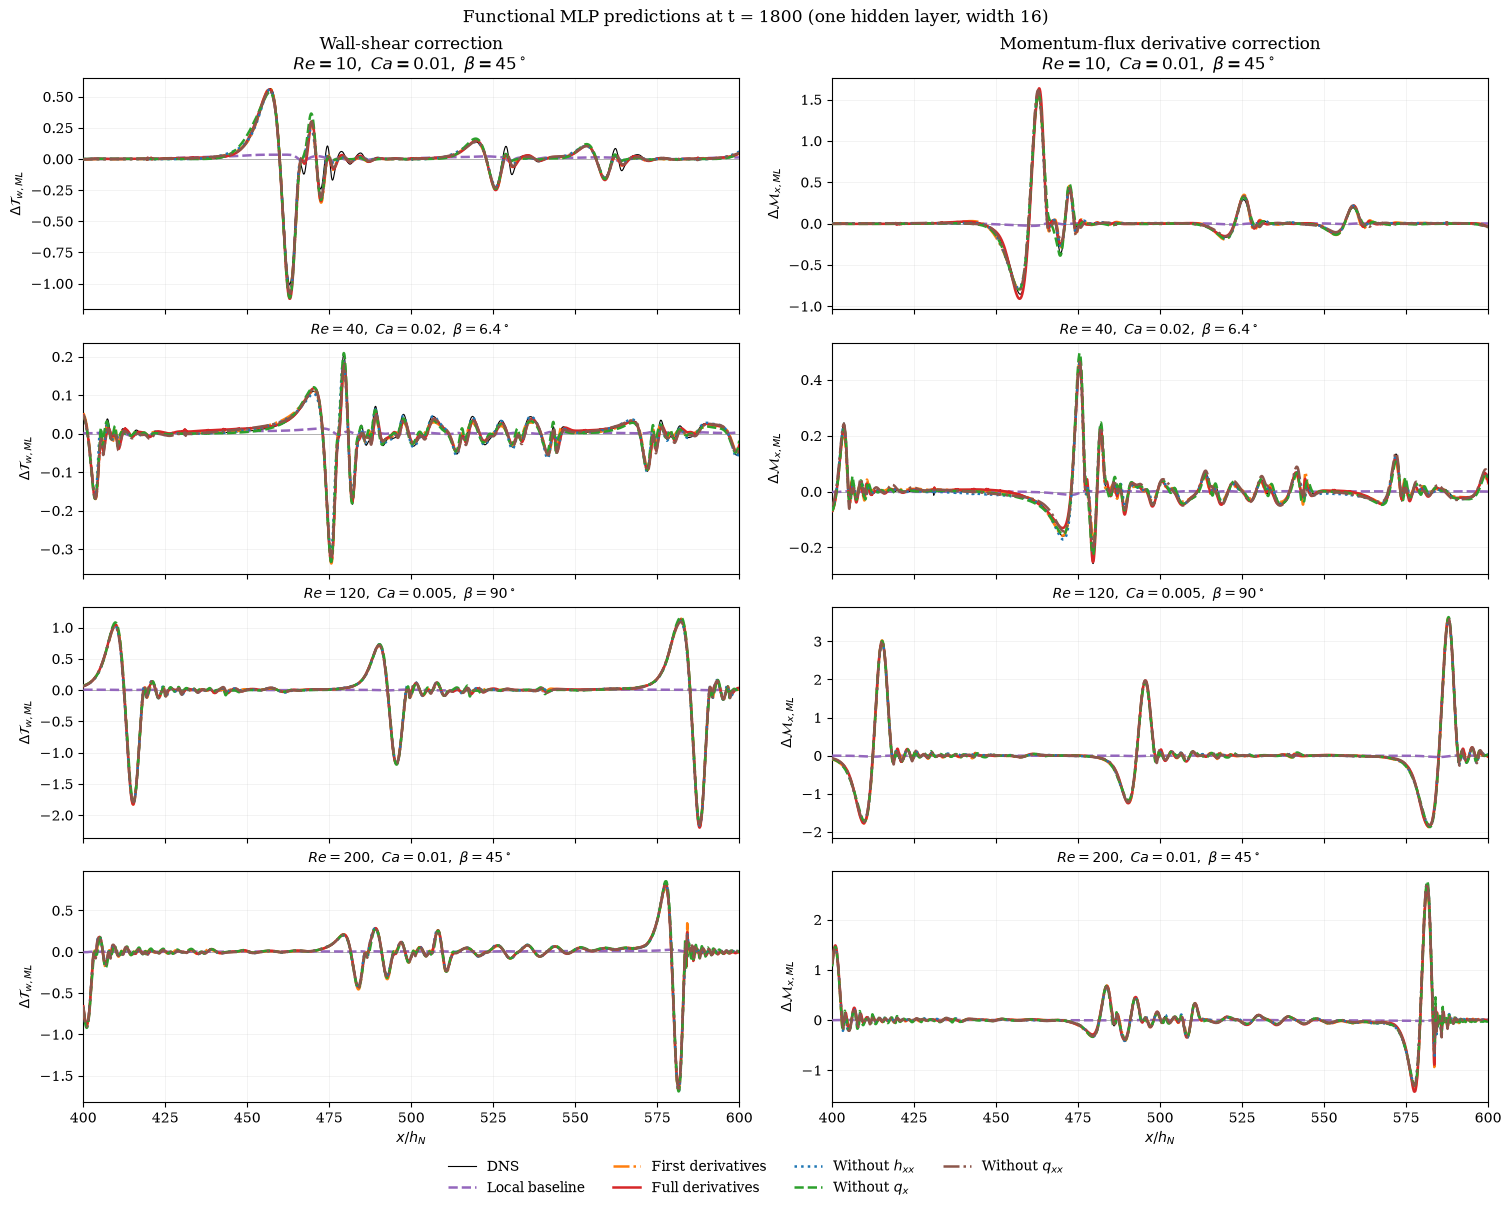

In [1]:
from pathlib import Path
import importlib.util
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
import torch

functional_root = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/ml-models/functional_mlp"
)
functional_runs = functional_root / "runs/ablation_01/layers1_width16"
functional_data = functional_root.parents[2] / "datasets/BasC/param_space/ClosureData"
# Load the model definition directly from the requested project.
model_spec = importlib.util.spec_from_file_location("report_functional_model", functional_root / "model.py")
functional_module = importlib.util.module_from_spec(model_spec)
model_spec.loader.exec_module(functional_module)
torch.set_num_threads(1)
functional_cases = [(10, 0.01, 45), (40, 0.02, 6.4),
                    (120, 0.005, 90), (200, 0.01, 45)]
functional_targets = ["delta_Tw_ML", "delta_Mx_ML"]
functional_variants = [
    ("local_baseline", "Local baseline", "tab:purple", "--"),
    ("first_derivatives", "First derivatives", "tab:orange", "-."),
    ("full_derivatives", "Full derivatives", "tab:red", "-"),
    ("without_h_xx", r"Without $h_{xx}$", "tab:blue", ":"),
    ("without_q_x", r"Without $q_x$", "tab:green", "--"),
    ("without_q_xx", r"Without $q_{xx}$", "tab:brown", "-."),
]
functional_models = {}
for variant, *_ in functional_variants:
    for target in functional_targets:
        checkpoint_path = functional_runs / variant / target / "seed42/best.pt"
        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
        if checkpoint.get("input_mode") != "local" or checkpoint["args"]["targets"] != [target]:
            raise ValueError(f"Unexpected model representation/target: {checkpoint_path}")
        model = functional_module.PhysicalMLP(checkpoint["architecture"], checkpoint["normalization"])
        model.load_state_dict(checkpoint["model"])
        model.eval()
        functional_models[(variant, target)] = (model, checkpoint["input_order"])

functional_predictions = {}
with plt.rc_context({"font.family": "serif", "font.size": 10, "pdf.fonttype": 42}):
    fig_functional, axes_functional = plt.subplots(
        4, 2, figsize=(15, 12), sharex=True, layout="constrained"
    )
    for row, (case_re, case_ca, case_beta) in enumerate(functional_cases):
        ca_case_tag = f"{case_ca:.3f}".replace(".", "_")
        beta_case_tag = f"{case_beta:g}".replace(".", "_")
        case_name = f"Re{case_re:03d}_Ca{ca_case_tag}_theta{beta_case_tag}"
        with h5py.File(functional_data / f"thinfilm_closure_data_{case_name}.h5", "r") as closure:
            x_case = np.asarray(closure["x"][:]).reshape(-1)
            t_case = np.asarray(closure["t"][:]).reshape(-1)
            matches = np.flatnonzero(np.isclose(t_case, 1800, rtol=0, atol=1e-8))
            if matches.size != 1:
                raise ValueError(f"No unique t=1800 snapshot: {case_name}")
            ti = int(matches[0])
            def read_functional_field(name):
                ds = closure[name]
                if ds.shape == (x_case.size, t_case.size):
                    return np.asarray(ds[:, ti])
                if ds.shape == (t_case.size, x_case.size):
                    return np.asarray(ds[ti, :])
                raise ValueError(f"Unexpected field shape: {name}")
            inputs = {name: read_functional_field(name)
                      for name in ["h", "q", "h_x", "q_x", "h_xx", "q_xx"]}
            for name in ["Re", "Ca", "angle"]:
                inputs[name] = np.full(x_case.size, float(closure["parameters"][name][()]))
            np.testing.assert_allclose([inputs["Re"][0], inputs["Ca"][0], np.rad2deg(inputs["angle"][0])],
                                       [case_re, case_ca, case_beta])
            truth = {name: read_functional_field(name) for name in functional_targets}
        visible = (x_case >= 400) & (x_case <= 600)
        functional_predictions[case_name + "_x"] = x_case
        for column, target in enumerate(functional_targets):
            ax = axes_functional[row, column]
            ax.plot(x_case[visible], truth[target][visible], color="black", linewidth=0.8,
                    label="DNS", zorder=2)
            functional_predictions[case_name + "_" + target + "_DNS"] = truth[target]
            for variant, label, color, linestyle in functional_variants:
                model, input_order = functional_models[(variant, target)]
                features = np.column_stack([inputs[name] for name in input_order]).astype(np.float32)
                if not np.all(np.isfinite(features)):
                    raise ValueError(f"Nonfinite model inputs: {case_name}")
                with torch.inference_mode():
                    prediction = model(torch.from_numpy(features)).numpy().reshape(-1)
                if not np.all(np.isfinite(prediction)):
                    raise ValueError(f"Nonfinite predictions: {variant}, {case_name}")
                functional_predictions[case_name + "_" + target + "_" + variant] = prediction
                ax.plot(x_case[visible], prediction[visible], color=color, linestyle=linestyle,
                        linewidth=1.8, alpha=1.0, label=label, zorder=3)
            ax.set_xlim(400, 600)
            ax.axhline(0, color="0.6", linewidth=0.5)
            ax.grid(alpha=0.2, linewidth=0.5)
            ax.set_ylabel(r"$\Delta\mathcal{T}_{w,ML}$" if column == 0 else r"$\Delta\mathcal{M}_{x,ML}$")
            ax.set_title(rf"$Re={case_re},\ Ca={case_ca:g},\ \beta={case_beta:g}^\circ$", fontsize=10)
    axes_functional[0, 0].set_title("Wall-shear correction\n" + axes_functional[0, 0].get_title())
    axes_functional[0, 1].set_title("Momentum-flux derivative correction\n" + axes_functional[0, 1].get_title())
    for ax in axes_functional[-1]:
        ax.set_xlabel(r"$x/h_N$")
    handles, labels = axes_functional[0, 0].get_legend_handles_labels()
    fig_functional.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
    fig_functional.suptitle("Functional MLP predictions at t = 1800 (one hidden layer, width 16)")
    functional_output = Path("section3_figures")
    functional_output.mkdir(parents=True, exist_ok=True)
    fig_functional.savefig(functional_output / "functional_MLP_Tw_Mx_t1800.pdf", format="pdf")
    fig_functional.savefig(functional_output / "functional_MLP_Tw_Mx_t1800.png", dpi=300)
    np.savez_compressed(functional_output / "functional_MLP_Tw_Mx_t1800_predictions.npz", **functional_predictions)
    plt.show()


## Functional MLP: local baseline versus first derivatives

Separate version of the four-simulation comparison at t = 1800, showing DNS and only the local-baseline and first-derivative models. Wall-shear correction is on the left and momentum-flux derivative correction on the right. All panels cover x/h_N = 400–600. The full six-variant figure is retained above.

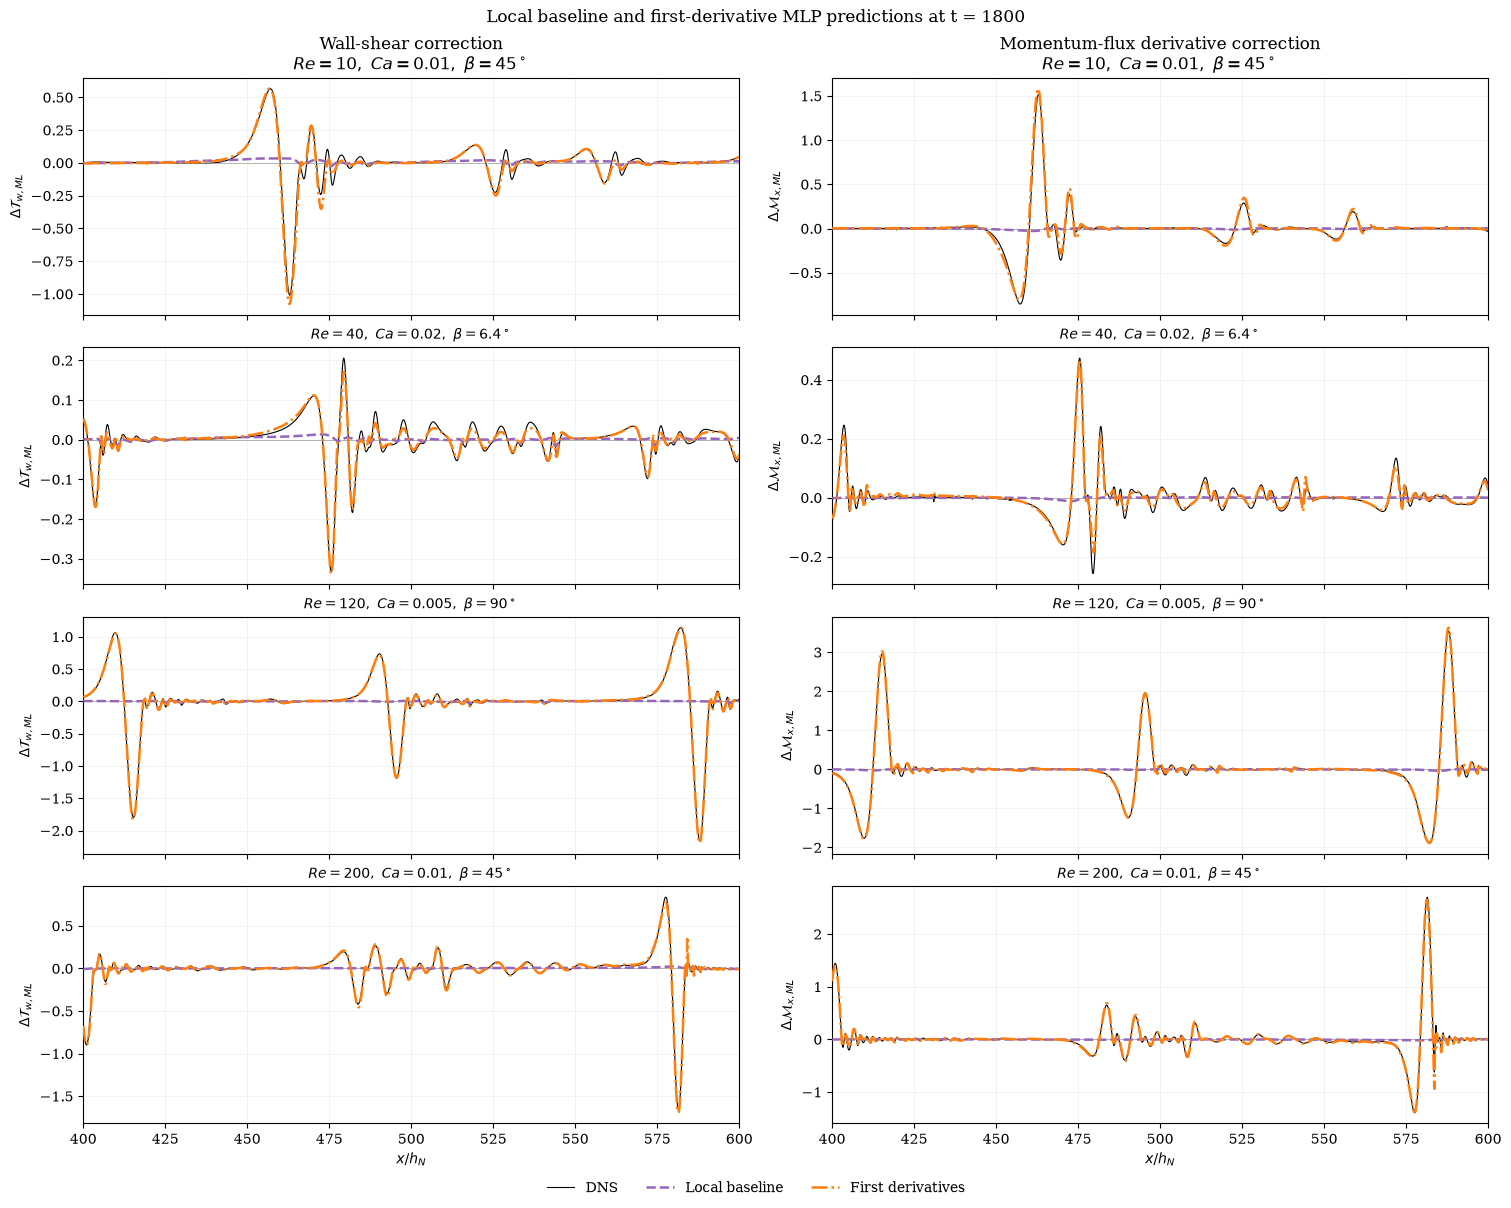

In [1]:
from pathlib import Path
import importlib.util
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
import torch

functional_root = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/"
    "codes/ml-models/functional_mlp"
)
functional_runs = functional_root / "runs/ablation_01/layers1_width16"
functional_data = functional_root.parents[2] / "datasets/BasC/param_space/ClosureData"
# Load the model definition directly from the requested project.
model_spec = importlib.util.spec_from_file_location("report_functional_model", functional_root / "model.py")
functional_module = importlib.util.module_from_spec(model_spec)
model_spec.loader.exec_module(functional_module)
torch.set_num_threads(1)
functional_cases = [(10, 0.01, 45), (40, 0.02, 6.4),
                    (120, 0.005, 90), (200, 0.01, 45)]
functional_targets = ["delta_Tw_ML", "delta_Mx_ML"]
functional_variants = [
    ("local_baseline", "Local baseline", "tab:purple", "--"),
    ("first_derivatives", "First derivatives", "tab:orange", "-."),
]
functional_models = {}
for variant, *_ in functional_variants:
    for target in functional_targets:
        checkpoint_path = functional_runs / variant / target / "seed42/best.pt"
        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
        if checkpoint.get("input_mode") != "local" or checkpoint["args"]["targets"] != [target]:
            raise ValueError(f"Unexpected model representation/target: {checkpoint_path}")
        model = functional_module.PhysicalMLP(checkpoint["architecture"], checkpoint["normalization"])
        model.load_state_dict(checkpoint["model"])
        model.eval()
        functional_models[(variant, target)] = (model, checkpoint["input_order"])

functional_predictions = {}
with plt.rc_context({"font.family": "serif", "font.size": 10, "pdf.fonttype": 42}):
    fig_functional, axes_functional = plt.subplots(
        4, 2, figsize=(15, 12), sharex=True, layout="constrained"
    )
    for row, (case_re, case_ca, case_beta) in enumerate(functional_cases):
        ca_case_tag = f"{case_ca:.3f}".replace(".", "_")
        beta_case_tag = f"{case_beta:g}".replace(".", "_")
        case_name = f"Re{case_re:03d}_Ca{ca_case_tag}_theta{beta_case_tag}"
        with h5py.File(functional_data / f"thinfilm_closure_data_{case_name}.h5", "r") as closure:
            x_case = np.asarray(closure["x"][:]).reshape(-1)
            t_case = np.asarray(closure["t"][:]).reshape(-1)
            matches = np.flatnonzero(np.isclose(t_case, 1800, rtol=0, atol=1e-8))
            if matches.size != 1:
                raise ValueError(f"No unique t=1800 snapshot: {case_name}")
            ti = int(matches[0])
            def read_functional_field(name):
                ds = closure[name]
                if ds.shape == (x_case.size, t_case.size):
                    return np.asarray(ds[:, ti])
                if ds.shape == (t_case.size, x_case.size):
                    return np.asarray(ds[ti, :])
                raise ValueError(f"Unexpected field shape: {name}")
            inputs = {name: read_functional_field(name)
                      for name in ["h", "q", "h_x", "q_x", "h_xx", "q_xx"]}
            for name in ["Re", "Ca", "angle"]:
                inputs[name] = np.full(x_case.size, float(closure["parameters"][name][()]))
            np.testing.assert_allclose([inputs["Re"][0], inputs["Ca"][0], np.rad2deg(inputs["angle"][0])],
                                       [case_re, case_ca, case_beta])
            truth = {name: read_functional_field(name) for name in functional_targets}
        visible = (x_case >= 400) & (x_case <= 600)
        functional_predictions[case_name + "_x"] = x_case
        for column, target in enumerate(functional_targets):
            ax = axes_functional[row, column]
            ax.plot(x_case[visible], truth[target][visible], color="black", linewidth=0.8,
                    label="DNS", zorder=2)
            functional_predictions[case_name + "_" + target + "_DNS"] = truth[target]
            for variant, label, color, linestyle in functional_variants:
                model, input_order = functional_models[(variant, target)]
                features = np.column_stack([inputs[name] for name in input_order]).astype(np.float32)
                if not np.all(np.isfinite(features)):
                    raise ValueError(f"Nonfinite model inputs: {case_name}")
                with torch.inference_mode():
                    prediction = model(torch.from_numpy(features)).numpy().reshape(-1)
                if not np.all(np.isfinite(prediction)):
                    raise ValueError(f"Nonfinite predictions: {variant}, {case_name}")
                functional_predictions[case_name + "_" + target + "_" + variant] = prediction
                ax.plot(x_case[visible], prediction[visible], color=color, linestyle=linestyle,
                        linewidth=1.8, alpha=1.0, label=label, zorder=3)
            ax.set_xlim(400, 600)
            ax.axhline(0, color="0.6", linewidth=0.5)
            ax.grid(alpha=0.2, linewidth=0.5)
            ax.set_ylabel(r"$\Delta\mathcal{T}_{w,ML}$" if column == 0 else r"$\Delta\mathcal{M}_{x,ML}$")
            ax.set_title(rf"$Re={case_re},\ Ca={case_ca:g},\ \beta={case_beta:g}^\circ$", fontsize=10)
    axes_functional[0, 0].set_title("Wall-shear correction\n" + axes_functional[0, 0].get_title())
    axes_functional[0, 1].set_title("Momentum-flux derivative correction\n" + axes_functional[0, 1].get_title())
    for ax in axes_functional[-1]:
        ax.set_xlabel(r"$x/h_N$")
    handles, labels = axes_functional[0, 0].get_legend_handles_labels()
    fig_functional.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
    fig_functional.suptitle("Local baseline and first-derivative MLP predictions at t = 1800")
    functional_output = Path("section3_figures")
    functional_output.mkdir(parents=True, exist_ok=True)
    fig_functional.savefig(functional_output / "functional_MLP_baseline_first_derivatives_Tw_Mx_t1800.pdf", format="pdf")
    fig_functional.savefig(functional_output / "functional_MLP_baseline_first_derivatives_Tw_Mx_t1800.png", dpi=300)
    np.savez_compressed(functional_output / "functional_MLP_baseline_first_derivatives_Tw_Mx_t1800_predictions.npz", **functional_predictions)
    plt.show()
